# Step 0 · Sector definition and extraction: underwater drones

This notebook builds the **underwater drones** sector from PATSTAT (Tutorial 0, Notebook 1: keywords and
classification codes combined) and validates it (PW kick-off: hand-label about 100 random families).

| Section | What it does |
|---|---|
| 1 | Setup: environment, configuration, labels, helper functions |
| 2 | Candidate pool: one SQL pass that collects every family that *could* belong to the sector |
| 3 | Application- and family-level data: applications, family year, titles, abstracts, CPC and IPC codes |
| 4 | The sector: five selection blocks, grey-zone exclusion rules, hand-labelled corrections |
| 5 | Block overlap |
| 6 | Labelling protocol and samples to label |
| 7 | Validation: precision, agreement, grey zones, recall, false positives, corrections |
| 8 | Lexical vs semantic retrieval (keywords, BM25, TF-IDF, Patent SBERT) and UMAP maps |
| 9 | Saved outputs (used by `02_clean`) |
| 10 | Summary: the numbers to report and the checks still open |

**Why two steps (SQL, then Python)?** SQL `LIKE` cannot match whole words, so `'%rov%'` would also catch
*improve* and *provide*. SQL therefore only collects a broad candidate pool (CPC codes and keyword phrases);
the exact rules, including whole-word acronyms, are applied in Python with regular expressions (`pw_utils`).

**Counting rules** (Tutorial 0, Notebook 2): one row per DOCDB family; family year = earliest priority year of
the family (minimum `earliest_filing_year` over its applications), 2000–2025; patents of invention only;
dummy applications excluded (Tutorial 1); years after `LAST_COMPLETE_YEAR` flagged as truncated, never read as
a decline. Language is **not** a filter for the sector: it only matters for the text methods (Section 8).

## 1 · Setup

To count **utility models** with the same query (robustness check, IM_Theory_0), uncomment the first line:
everything is then written to `outputs/<env>/step0_UM/` and the PI outputs are untouched.

In [1]:
# %env PW_IPR_TYPE=UM
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sqlalchemy import func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS203_APPLN_ABSTR,
    TLS209_APPLN_IPC,
    TLS224_APPLN_CPC,
)

sys.path.append(str(Path.cwd()))
import config as C
from pw_utils import (BLOCKS, EXCLUSIONS, apply_blocks, compile_any, fetch_by_ids, flags_by_family, grey_zone_flags,
                      precision_table, regex_to_like_phrases, summarise_blocks, wilson)

C.OUT_STEP0.mkdir(parents=True, exist_ok=True)
(C.OUT_STEP0 / "raw").mkdir(exist_ok=True)

patstat = PatstatClient(env=C.ENV)
db = patstat.orm()

print(f"Sector: {C.SECTOR_NAME} | env: {C.ENV} | years {C.YEAR_MIN}-{C.YEAR_MAX} "
      f"| last complete year {C.LAST_COMPLETE_YEAR} | IPR type {C.IPR_TYPE}")

Sector: Underwater drones | env: PROD | years 2000-2025 | last complete year 2022 | IPR type PI


In [2]:
# ---------------------------------------------------------------- helpers

def fetch_by_family(make_query, family_ids):
    """Chunked IN (...) queries (see pw_utils.fetch_by_ids)."""
    return fetch_by_ids(patstat, make_query, family_ids)


def stripped(col):
    """Classification symbol without blanks: 'B63G   8/00' -> 'B63G8/00' (PATSTAT pads symbols, Tutorial 0)."""
    return func.replace(col, " ", "")


def sql_prefix_any(col, prefixes):
    s = stripped(col)
    return or_(*(s.like(p.replace(" ", "") + "%") for p in prefixes))


def sql_like_any(col, phrases):
    low = func.lower(col)
    return or_(*(low.like(f"%{p}%") for p in phrases))

**Labels.** Every `.csv` in `labels/` is read (see `labels/README.md`): one row per family, `is_relevant` = 0/1
(strict rule, used for the sector and every validation number), `is_relevant_broad` = 0/1 (broad rule, used only as
an upper bound in 7.1 and 7.3; if missing it is set equal to `is_relevant`), `sample` = where the family comes from (`sector`, `candidates`, `block5`, `broad_net`, `broad_net_outside`,
`discovery`, `other`), `grey_zone` and `note` (the reason for the label). Labels are read **before** the queries, because the families
labelled relevant must be downloaded even when the query misses them (Section 4, corrections).

In [3]:
def load_labels():
    """All label files in labels/ (utf-8-sig: files saved by Excel start with a BOM); one row per family."""
    frames = []
    for f in sorted(C.LABEL_DIR.glob("*.csv")):
        d = pd.read_csv(f, encoding="utf-8-sig")
        if C.LABEL_COL not in d.columns or "docdb_family_id" not in d.columns:
            print(f"skipped {f.name}: needs docdb_family_id and {C.LABEL_COL}")
            continue
        d = d[pd.to_numeric(d[C.LABEL_COL], errors="coerce").isin([0, 1])].copy()
        d[C.LABEL_COL] = d[C.LABEL_COL].astype(int)
        broad = pd.to_numeric(d[C.LABEL_COL_BROAD], errors="coerce") if C.LABEL_COL_BROAD in d else pd.Series(np.nan, d.index)
        # the broad rule includes everything the strict rule includes
        d[C.LABEL_COL_BROAD] = np.maximum(broad.fillna(d[C.LABEL_COL]), d[C.LABEL_COL]).astype(int)
        d["docdb_family_id"] = d["docdb_family_id"].astype("int64")
        d["label_file"] = f.name
        frames.append(d)
    cols = ["docdb_family_id", C.LABEL_COL, C.LABEL_COL_BROAD, "label_file", "sample", "grey_zone", "label_b"]
    if not frames:
        return pd.DataFrame(columns=cols)
    out = pd.concat(frames, ignore_index=True).drop_duplicates("docdb_family_id", keep="last")
    for c in ["sample", "grey_zone"]:
        if c not in out:
            out[c] = ""
        out[c] = out[c].fillna("").astype(str).str.strip()
    return out.reset_index(drop=True)


def load_second_labels():
    """Independent second labels (labels/second/<labeller>.csv): docdb_family_id + is_relevant (0/1).
    One column per labeller, named after the file. They never change the sector: they only measure agreement (7.2)."""
    out = None
    for f in sorted(C.SECOND_LABEL_DIR.glob("*.csv")) if C.SECOND_LABEL_DIR.exists() else []:
        d = pd.read_csv(f, encoding="utf-8-sig")
        if C.LABEL_COL not in d.columns or "docdb_family_id" not in d.columns:
            print(f"skipped second/{f.name}: needs docdb_family_id and {C.LABEL_COL}")
            continue
        d = d[pd.to_numeric(d[C.LABEL_COL], errors="coerce").isin([0, 1])]
        d = d[["docdb_family_id", C.LABEL_COL]].astype("int64").drop_duplicates("docdb_family_id", keep="last")
        d = d.rename(columns={C.LABEL_COL: f"lab_{f.stem}"})
        out = d if out is None else out.merge(d, on="docdb_family_id", how="outer")
    return out if out is not None else pd.DataFrame(columns=["docdb_family_id"])


labels = load_labels()
second_labels = load_second_labels()
print(f"Second labellers in {C.SECOND_LABEL_DIR}/: {[c[4:] for c in second_labels.columns if c.startswith('lab_')]}")
print(f"Labelled families in {C.LABEL_DIR}/: {len(labels):,}")
if not labels.empty:
    display(labels.groupby("sample").agg(families=("docdb_family_id", "size"), relevant_strict=(C.LABEL_COL, "sum"),
                                         relevant_broad=(C.LABEL_COL_BROAD, "sum")))

# used for the corrections of Section 4 (strict rule)
labelled_relevant = set(labels.loc[labels[C.LABEL_COL] == 1, "docdb_family_id"])
labelled_not_relevant = set(labels.loc[labels[C.LABEL_COL] == 0, "docdb_family_id"])

Second labellers in labels/second/: []
Labelled families in labels/: 608


,families,relevant_strict,relevant_broad
sample,,,
block5,3,2,3
broad_net,64,8,15
broad_net_outside,86,10,19
candidates,100,59,67
discovery,164,72,98
other,6,2,4
sector,185,160,173


## 2 · Candidate pool (SQL)

A family enters the pool if one of its PI applications carries a block-1 or block-4 CPC code, or if a title or
abstract contains one of the keyword phrases of blocks 2 and 3, or a title contains ROV, AUV or UUV (block 5).
The families labelled relevant are added too (they may lie outside the query). Dummy applications (`appln_id` 0
or above 900,000,000, Tutorial 1) are excluded from every query.

In [4]:
family_id = TLS201_APPLN.docdb_family_id.label("docdb_family_id")
kw_phrases = regex_to_like_phrases(C.SPECIFIC_KEYWORDS + C.GENERIC_KEYWORDS) + list(C.BLOCK6_SQL_PHRASES)


def real_pi(q):
    """Patents of invention, no dummy applications."""
    return q.filter(TLS201_APPLN.ipr_type == C.IPR_TYPE,
                    TLS201_APPLN.appln_id > 0, TLS201_APPLN.appln_id < C.INVALID_APPLN_ID)


pool_cpc = real_pi(db.query(family_id)
                   .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
                   .filter(sql_prefix_any(TLS224_APPLN_CPC.cpc_class_symbol, C.BLOCK1_CPC + C.BLOCK4_CPC)))
pool_title = real_pi(db.query(family_id)
                     .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                     .filter(sql_like_any(TLS202_APPLN_TITLE.appln_title, kw_phrases)))
pool_abstract = real_pi(db.query(family_id)
                        .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                        .filter(sql_like_any(TLS203_APPLN_ABSTR.appln_abstract, kw_phrases)))
title_low = func.lower(TLS202_APPLN_TITLE.appln_title)
pool_b5 = real_pi(db.query(family_id)
                  .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                  .filter(or_(*(title_low.like(p) for p in C.BLOCK5_SQL_PATTERNS))))

pool_ids = pd.DataFrame(patstat.df(pool_cpc.union(pool_title, pool_abstract, pool_b5)))
pool_ids = pool_ids["docdb_family_id"].dropna().astype("int64").drop_duplicates().tolist()
query_pool = set(pool_ids)
pool_ids = sorted(query_pool | labelled_relevant)
print(f"Candidate pool: {len(query_pool):,} families from the query + "
      f"{len(set(pool_ids) - query_pool):,} labelled relevant outside it | SQL phrases: {len(kw_phrases)}")

Candidate pool: 46,138 families from the query + 3 labelled relevant outside it | SQL phrases: 51


## 3 · Application- and family-level data

For every candidate family we download its PI applications and keep the families whose **family year** (earliest
priority of the family) falls in 2000–2025. Titles, abstracts and codes are kept per application and pooled per
family (the two matching levels of Section 4).

In [5]:
apps = fetch_by_family(
    lambda ids: real_pi(db.query(
        TLS201_APPLN.docdb_family_id, TLS201_APPLN.inpadoc_family_id, TLS201_APPLN.appln_id,
        TLS201_APPLN.appln_auth, TLS201_APPLN.appln_kind, TLS201_APPLN.appln_filing_date,
        TLS201_APPLN.appln_filing_year, TLS201_APPLN.earliest_filing_year, TLS201_APPLN.earliest_publn_year,
        TLS201_APPLN.granted, TLS201_APPLN.docdb_family_size, TLS201_APPLN.nb_citing_docdb_fam,
    ).filter(TLS201_APPLN.docdb_family_id.in_(ids))),
    pool_ids,
)
valid_year = apps["earliest_filing_year"].where(apps["earliest_filing_year"] != C.MISSING_YEAR)
apps["family_year"] = valid_year.groupby(apps["docdb_family_id"]).transform("min")
apps = apps[apps["family_year"].between(C.YEAR_MIN, C.YEAR_MAX)].copy()
apps["family_year"] = apps["family_year"].astype(int)
family_ids = apps["docdb_family_id"].drop_duplicates().tolist()
print(f"Applications: {len(apps):,} | families with family year {C.YEAR_MIN}-{C.YEAR_MAX}: {len(family_ids):,}")

Applications: 48,842 | families with family year 2000-2025: 31,976


In [6]:
def by_family(model, *cols, extra=None):
    """Rows of `model` (joined on appln_id) for the PI applications of the candidate families."""
    def make(ids):
        q = real_pi(db.query(TLS201_APPLN.docdb_family_id, *cols)
                    .join(model, TLS201_APPLN.appln_id == model.appln_id)
                    .filter(TLS201_APPLN.docdb_family_id.in_(ids)))
        return q.filter(extra) if extra is not None else q
    return fetch_by_family(make, family_ids)


titles = by_family(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id, TLS202_APPLN_TITLE.appln_title,
                   TLS202_APPLN_TITLE.appln_title_lg)
abstracts = by_family(TLS203_APPLN_ABSTR, TLS203_APPLN_ABSTR.appln_id, TLS203_APPLN_ABSTR.appln_abstract,
                      TLS203_APPLN_ABSTR.appln_abstract_lg)
cpc = by_family(TLS224_APPLN_CPC, TLS224_APPLN_CPC.appln_id, TLS224_APPLN_CPC.cpc_class_symbol)
cpc["cpc"] = cpc["cpc_class_symbol"].str.replace(" ", "", regex=False)
ipc = by_family(TLS209_APPLN_IPC, TLS209_APPLN_IPC.appln_id, TLS209_APPLN_IPC.ipc_class_symbol)
if ipc.empty:
    ipc = pd.DataFrame(columns=["docdb_family_id", "appln_id", "ipc_class_symbol", "ipc"])
else:
    ipc["ipc"] = ipc["ipc_class_symbol"].str.replace(" ", "", regex=False)
print(f"Titles: {len(titles):,} | abstracts: {len(abstracts):,} | CPC rows: {len(cpc):,} | IPC rows: {len(ipc):,}")

Titles: 48,670 | abstracts: 45,515 | CPC rows: 265,322 | IPC rows: 160,056


In [7]:
def join_unique(s):
    vals = [str(v).strip() for v in s.dropna().unique() if str(v).strip()]
    return " || ".join(vals)


def code_lists(df, col, key):
    return df.groupby(key)[col].agg(lambda s: sorted(set(s)))


def as_list(v):
    return v if isinstance(v, list) else []


# ---- one row per application
app_units = apps[["docdb_family_id", "appln_id"]].copy()
app_units["titles"] = app_units["appln_id"].map(titles.set_index("appln_id")["appln_title"]).fillna("")
app_units["abstracts"] = app_units["appln_id"].map(abstracts.set_index("appln_id")["appln_abstract"]).fillna("")
app_units["cpc_codes"] = app_units["appln_id"].map(code_lists(cpc, "cpc", "appln_id")).apply(as_list)
app_units["ipc_codes"] = app_units["appln_id"].map(code_lists(ipc, "ipc", "appln_id")).apply(as_list)

# ---- one row per family (texts and codes pooled)
fam = (apps.groupby("docdb_family_id")
       .agg(family_year=("family_year", "first"), n_applications=("appln_id", "nunique"),
            docdb_family_size=("docdb_family_size", "max"))
       .reset_index())
first_app = apps.sort_values(["docdb_family_id", "appln_filing_date", "appln_id"]).drop_duplicates("docdb_family_id")
fam["first_office"] = fam["docdb_family_id"].map(first_app.set_index("docdb_family_id")["appln_auth"])
fam["titles"] = fam["docdb_family_id"].map(titles.groupby("docdb_family_id")["appln_title"].agg(join_unique)).fillna("")
fam["abstracts"] = fam["docdb_family_id"].map(abstracts.groupby("docdb_family_id")["appln_abstract"].agg(join_unique)).fillna("")
fam["cpc_codes"] = fam["docdb_family_id"].map(code_lists(cpc, "cpc", "docdb_family_id")).apply(as_list)
fam["ipc_codes"] = fam["docdb_family_id"].map(code_lists(ipc, "ipc", "docdb_family_id")).apply(as_list)

# one English title and abstract per family, for labelling and NLP (NOT a filter for the sector)
def lang(col):
    """Language codes as stored on TIP may carry blanks or capitals: normalise before comparing."""
    return col.fillna("").astype(str).str.strip().str.lower()


def first_text(df, text_col, english_only):
    ok = df[text_col].fillna("").astype(str).str.strip().ne("")
    if english_only:
        ok &= lang(df[text_col + "_lg"]) == "en"
    return df[ok].drop_duplicates("docdb_family_id").set_index("docdb_family_id")[text_col]


print("Title languages:", lang(titles["appln_title_lg"]).value_counts().head(5).to_dict())
print("Abstract languages:", lang(abstracts["appln_abstract_lg"]).value_counts().head(5).to_dict())
fam["abstract_en"] = fam["docdb_family_id"].map(first_text(abstracts, "appln_abstract", True))
# English title; if a family has none, its title in another language (one title per application in PATSTAT)
fam["title_en"] = (fam["docdb_family_id"].map(first_text(titles, "appln_title", True))
                   .fillna(fam["docdb_family_id"].map(first_text(titles, "appln_title", False))))
print(f"Families with a title: {fam['title_en'].notna().mean():.1%}")
fam["has_en_abstract"] = fam["abstract_en"].notna()
print(f"Units: {len(app_units):,} applications, {len(fam):,} families | with English abstract: {fam['has_en_abstract'].mean():.1%}")

Title languages: {'en': 44075, 'de': 1373, 'es': 653, 'fr': 500, 'pt': 421}
Abstract languages: {'en': 41695, 'de': 888, 'es': 707, 'fr': 552, 'ko': 486}
Families with a title: 100.0%
Units: 48,842 applications, 31,976 families | with English abstract: 97.1%


## 4 · The sector

**Selection blocks** (a family is selected if at least one fires):

| Block | Rule |
|---|---|
| 1 · CPC | `B63G2008/002, 004, 005, 007, 008` (unmanned underwater vessels) **and** an underwater term in title or abstract |
| 2 · Specific keywords | a specific keyword (e.g. *autonomous underwater*, *underwater glider*, *robotic fish*) in title or abstract |
| 3 · Generic keywords | *remotely operated vehicle*, *underwater robot*, ... in the **title**, or in the abstract with a `B63` or `B25J` code |
| 4 · Neighbouring codes | `B63G8/` or `B63C11/` **and** a robot term (*robot*, *drone*, *ROV*, *AUV*, *UUV*, ...) |
| 5 · Acronym in the title | *ROV*, *AUV* or *UUV* as a whole word in the title |
| 6 · Vehicle + task | *underwater (…) vehicle*, *uninhabited underwater*, *underwater (…) glider* **and** an operating task (path, obstacle, navigation, positioning, depth control, docking, autonomous, unmanned…); or *underwater/subsea (…) robot* anywhere (added after the PROD recall check, 7.4 and 8.2) |

**Grey-zone exclusion rule** (`config.EXCLUSION_RULES`): a selected family is removed when its title is about an
**energy device or offshore structure** (turbines, generators, energy supply, wind farms, propellers...) **and**
the title has no vehicle term (robot, ROV, AUV, unmanned, vehicle, inspection, monitoring...). This applies the labelling rule of Section 6 to the whole sector: offshore-wind
inspection drones stay in, wind-farm structures where an ROV is only mentioned go out.

**Hand-labelled corrections** (`USE_LABEL_CORRECTIONS`): families labelled 0 leave the sector, families labelled 1
that the rules miss enter it. They fix the cases the rules cannot see; their number is reported in 7.6.

The rules are applied at two **matching levels**, both kept: *application* (code and words on the same
application) and *family* (texts and codes of all the family's applications pooled, Tutorial 1: it recovers
inventions whose English text sits on another member of the family). `MATCH_LEVEL` (default `family`) decides.
All regular expressions live in `config.py`; acronyms are whole words, so *rov* does not match *improve*.

In [8]:
FLAGS = BLOCKS + ["has_cpc"] + EXCLUSIONS
RX_SPECIFIC, RX_GENERIC = compile_any(C.SPECIFIC_KEYWORDS), compile_any(C.GENERIC_KEYWORDS)

fam_level = apply_blocks(fam)
app_level = flags_by_family(apply_blocks(app_units))
app_level = summarise_blocks(app_level.reindex(fam["docdb_family_id"], fill_value=False)).reset_index()

fam["in_sector_family"] = fam_level["in_sector"].values
fam["in_sector_application"] = fam["docdb_family_id"].map(app_level.set_index("docdb_family_id")["in_sector"]).fillna(False)
chosen = fam_level if C.MATCH_LEVEL == "family" else fam[["docdb_family_id"]].merge(app_level, on="docdb_family_id", how="left")
for col in FLAGS + ["matched", "excluded", "n_blocks", "block_combo"]:
    fam[col] = chosen[col].values
fam["in_sector_rules"] = chosen["in_sector"].values        # the sector given by the rules (what Section 7 validates)
fam = pd.concat([fam, grey_zone_flags(fam)], axis=1)
fam["is_truncated"] = fam["family_year"] > C.LAST_COMPLETE_YEAR

# hand-labelled corrections
fam["corr_removed"] = C.USE_LABEL_CORRECTIONS & fam["in_sector_rules"] & fam["docdb_family_id"].isin(labelled_not_relevant)
fam["corr_added"] = C.USE_LABEL_CORRECTIONS & ~fam["in_sector_rules"] & fam["docdb_family_id"].isin(labelled_relevant)
fam["in_sector"] = (fam["in_sector_rules"] & ~fam["corr_removed"]) | fam["corr_added"]
fam.loc[fam["corr_added"], "block_combo"] = "added by label"

sector = fam[fam["in_sector"]].copy()
rule_sector = fam[fam["in_sector_rules"]].copy()
sector_ids = set(sector["docdb_family_id"])
print(f"Families selected by the blocks ({C.MATCH_LEVEL} level): {fam['matched'].sum():,} (out of {len(fam):,} candidates)")
print(f"  removed by the grey-zone exclusion rules: {(fam['matched'] & fam['excluded']).sum():,}")
print(f"  = sector given by the rules: {len(rule_sector):,} | application level: {fam['in_sector_application'].sum():,} "
      f"| family level: {fam['in_sector_family'].sum():,}")
print(f"  hand-labelled corrections: -{fam['corr_removed'].sum():,} labelled not relevant, "
      f"+{fam['corr_added'].sum():,} labelled relevant outside the rules")
print(f"SECTOR: {len(sector):,} families | truncated (> {C.LAST_COMPLETE_YEAR}): {sector['is_truncated'].sum():,}")

Families selected by the blocks (family level): 15,949 (out of 31,976 candidates)
  removed by the grey-zone exclusion rules: 173
  = sector given by the rules: 15,776 | application level: 15,755 | family level: 15,776
  hand-labelled corrections: -51 labelled not relevant, +29 labelled relevant outside the rules
SECTOR: 15,754 families | truncated (> 2022): 5,762


### 4.1 Grey zones

Topic flags (`config.GREY_ZONE_PATTERNS`, plus offshore-wind CPC codes) count how many sector families touch each
grey zone; the families the exclusion rules removed are listed below, so the team can check them.

In [9]:
GZ = [c for c in fam.columns if c.startswith("gz_")]
display(pd.DataFrame({"sector families": sector[GZ].sum(), "share of sector (%)": sector[GZ].mean() * 100}).round(1))
excl = fam[fam["matched"] & fam["excluded"]]
print(f"\nFamilies removed by the exclusion rules: {len(excl)}")
display(excl[["docdb_family_id", "title_en"] + [c for c in EXCLUSIONS if excl[c].any()]])

,sector families,share of sector (%)
gz_offshore_wind,77,0.5
gz_hybrid_surface,642,4.1
gz_hybrid_air,1050,6.7
gz_outside_sea,200,1.3



Families removed by the exclusion rules: 173


,docdb_family_id,title_en,ex_energy_device
953,33016126,Wind power offshore facility for converting wi...,True
1040,34063562,Wave rotor based power and propulsion generati...,True
1411,35516011,A deployment and retrieval apparatus for subme...,True
1478,36079810,Conduit tandem airscrew propeller,True
2068,38433131,Underwater power generation using underwater t...,True
...,...,...,...
29319,96354244,Wireless energy supply and control system of d...,True
29929,97001230,"Operation and maintenance method, device and s...",True
30011,97106845,UNDERWATER ENERGY TRANSFER SYSTEM,True
31419,98793664,Underwater vector type shaftless pump jet prop...,True


### 4.2 CPC coverage: families without CPC codes

The blocks use CPC, not IPC: the CPC contains the IPC main groups in more detail, and the codes for unmanned
underwater vessels (`B63G2008/...`) exist only in the CPC. A family without any CPC code can enter only through
keywords. If such families are many, and concentrated in some offices, the sector under-counts those countries.

In [10]:
cov = pd.DataFrame({
    "candidates": fam.groupby("first_office").size(),
    "candidates without CPC": fam[~fam["has_cpc"]].groupby("first_office").size(),
    "sector families": sector.groupby("first_office").size(),
    "sector families without CPC (keywords only)": sector[~sector["has_cpc"]].groupby("first_office").size(),
}).fillna(0).astype(int).sort_values("candidates", ascending=False)
cov = pd.concat([cov.head(12), cov.iloc[12:].sum().to_frame("other offices").T, cov.sum().to_frame("total").T])
cov["% candidates without CPC"] = (cov["candidates without CPC"] / cov["candidates"].replace(0, np.nan) * 100).round(1)
display(cov)

,candidates,candidates without CPC,sector families,sector families without CPC (keywords only),% candidates without CPC
CN,20431,2989,12633,2013,14.6
US,2599,0,684,0,0.0
KR,2500,155,859,94,6.2
DE,1066,1,125,0,0.1
WO,1021,2,340,2,0.2
RU,658,210,239,69,31.9
GB,609,54,172,20,8.9
JP,604,332,203,131,55.0
FR,580,0,90,0,0.0
EP,384,0,81,0,0.0


## 5 · Block overlap

How many families each block brings alone, and how many come from several blocks. Together with the block
precision of 7.1, this shows how precise and how important each block is.

,families
block_combo,
b6,3830
b3 + b6,2007
b2 + b6,1749
b3 + b4 + b6,1264
b4,889
b1,785
b5,726
b2 + b5 + b6,638
b2,589


,families with the block,only this block
b1_cpc,2532,785
b2_specific,4530,589
b3_generic,4359,132
b4_neighbour,4275,889
b5_acronym_title,2019,726
b6_vehicle_task,11714,3830


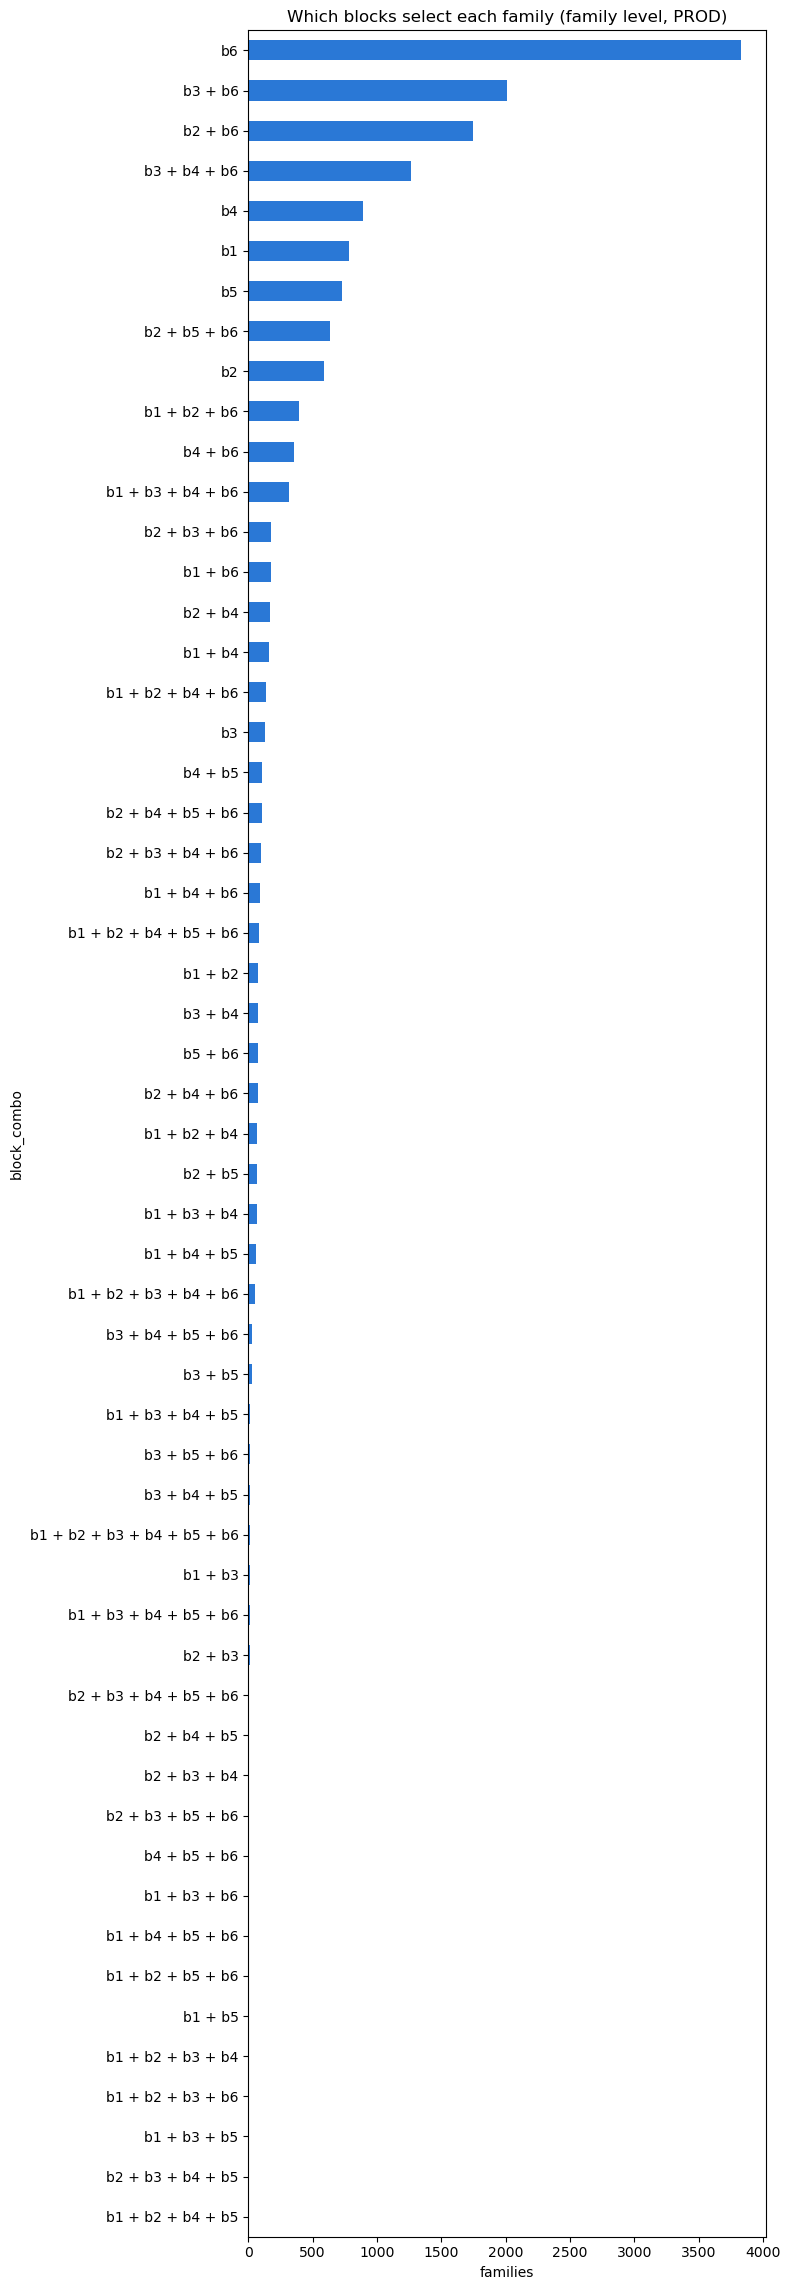

In [11]:
combo_counts = rule_sector["block_combo"].value_counts()
display(combo_counts.to_frame("families"))
alone = {b: int((rule_sector[b] & (rule_sector["n_blocks"] == 1)).sum()) for b in BLOCKS}
total = {b: int(rule_sector[b].sum()) for b in BLOCKS}
display(pd.DataFrame({"families with the block": total, "only this block": alone}))

fig, ax = plt.subplots(figsize=(8, 0.4 * len(combo_counts) + 1))
combo_counts.sort_values().plot.barh(ax=ax, color="#2a78d6")
ax.set_xlabel("families")
ax.set_title(f"Which blocks select each family ({C.MATCH_LEVEL} level, {C.ENV})")
plt.tight_layout()
fig.savefig(C.OUT_STEP0 / "block_overlap.png", dpi=150)
plt.show()

## 6 · Labelling protocol and samples

**Labelling protocol** (for the technical appendix):
1. **Definition** (`config.LABEL_DEFINITION`): an underwater drone is an unmanned vehicle that moves and works under
   water (ROVs, AUVs and UUVs, underwater gliders, robotic fish, seabed crawlers, hybrid vehicles that operate under
   water). The sector includes the drone itself, its parts (hull, propulsion, buoyancy, power, sensors, manipulators,
   tools carried or operated by it), its infrastructure (launch and recovery, docking, charging, tethers) and the
   methods to control, navigate and coordinate it.
2. **Rules.** Each family gets two labels. The **strict** rule defines the sector; the **broad** rule is kept only
   as a sensitivity check (an upper bound of precision), so the choice of rule is visible in the appendix.
   - `is_relevant` (**strict**) = 1 only if an underwater drone is the **subject** of the patent: the drone itself, a
     part or tool designed for one (the drone is named in the title or abstract), its infrastructure, or a method
     to control, navigate or coordinate it. 0 if no drone is involved, if one is only mentioned in passing ("without
     the need for divers or an ROV"), if an ROV only installs or operates generic subsea equipment (connectors,
     clamps, risers), or if the vehicle is not stated to be unmanned.
   - `is_relevant_broad` (**broad**) = 1 if the patent matches the definition **even partly**: also generic subsea
     equipment operated by an ROV, vehicles whose crew is not stated, submerged units of surface systems.
   - Always `is_relevant` ≤ `is_relevant_broad`. The reason goes in `note`.
3. **Grey zones** (write the zone in `grey_zone`, values in `config.GREY_ZONE_VALUES`):

   | Grey zone | `is_relevant` (strict) = 1 | strict = 0, broad = 1 | both 0 |
   |---|---|---|---|
   | offshore wind (`offshore_wind`) | a drone, its part or tool that inspects, maintains or installs wind farms | – | structures where an ROV is only mentioned |
   | surface–underwater (`hybrid_surface`) | an unmanned surface vessel that launches or recovers an underwater drone | submerged units of wave-driven or towed surface systems | surface drones alone |
   | air–water (`hybrid_air`) | a vehicle designed to fly and to move under water | multi-environment craft where water is one of many media | craft that only land on water |
   | crew not stated (`crew_not_stated`) | – (strict needs "unmanned", "autonomous", "remote", ROV/AUV/robot) | submersibles and vessels with no crew stated | crewed submarines, life support, passengers |
   | components (`generic_component`) | parts designed for a named underwater drone | parts for "submersibles" or "subsea equipment"; equipment installed by an ROV | generic marine parts (ship propellers, motors) |
   | outside the sea (`outside_sea`) | – | ROVs in nuclear pools or tanks | robots in dry environments |
   | other (`other`) | – | towed or tethered bodies, moored floating devices, test models | landers, floats, platforms without propulsion |

4. **How**: the labels are produced by applying the definition and the rule to each title and abstract, one family
   at a time, with the reason written in `note`; declare the method in the generative-AI statement.

**Samples written to `outputs/<env>/step0/`** (one row per family, **without** the flags that selected it, so
the labeller is not anchored; the flags are kept apart in `label_samples_key.csv`). Label them and save them in
`labels/` (e.g. `labels/sector_prod.csv`), with the `sample` column as written:

| File | Families | Used for |
|---|---|---|
| `label_sample_sector.csv` | `SAMPLE_SIZE` random sector families not labelled yet | precision (7.1) |
| `label_sample_broad_net.csv` | `BROAD_SAMPLE_SIZE` random families of the broad net outside the sector | recall (7.4) |
| `label_discovery.csv` (Section 8.2) | top families of BM25 and SBERT outside the sector | what text retrieval finds that the rules miss |

**Broad net.** A deliberately wide query (`config.BROAD_IPC`, `BROAD_CPC`, `BROAD_KEYWORDS`: IPC codes for
underwater vessels, sonar and acoustic communication, and generic phrases such as *underwater vehicle*). It catches
many non-relevant families, which is why it is not the sector; but the relevant families it finds outside the
sector are an estimate of what the sector misses.

In [12]:
b_cpc = real_pi(db.query(family_id).join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
                .filter(sql_prefix_any(TLS224_APPLN_CPC.cpc_class_symbol, C.BROAD_CPC)))
b_ipc = real_pi(db.query(family_id).join(TLS209_APPLN_IPC, TLS201_APPLN.appln_id == TLS209_APPLN_IPC.appln_id)
                .filter(sql_prefix_any(TLS209_APPLN_IPC.ipc_class_symbol, C.BROAD_IPC)))
b_title = real_pi(db.query(family_id).join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                  .filter(sql_like_any(TLS202_APPLN_TITLE.appln_title, C.BROAD_KEYWORDS)))
b_abs = real_pi(db.query(family_id).join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                .filter(sql_like_any(TLS203_APPLN_ABSTR.appln_abstract, C.BROAD_KEYWORDS)))
broad_ids = pd.DataFrame(patstat.df(b_cpc.union(b_ipc, b_title, b_abs)))["docdb_family_id"].astype("int64").unique()
broad_years = fetch_by_family(
    lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id,
                                 func.min(TLS201_APPLN.earliest_filing_year).label("family_year"))
                        .filter(TLS201_APPLN.docdb_family_id.in_(ids))
                        .filter(TLS201_APPLN.earliest_filing_year != C.MISSING_YEAR))
    .group_by(TLS201_APPLN.docdb_family_id),
    broad_ids,
)
broad_set = set(broad_years.loc[broad_years["family_year"].between(C.YEAR_MIN, C.YEAR_MAX), "docdb_family_id"])
rule_ids = set(rule_sector["docdb_family_id"])
broad_outside = broad_set - rule_ids
print(f"Broad net: {len(broad_set):,} families | in the sector: {len(broad_set & rule_ids):,} "
      f"| outside the sector: {len(broad_outside):,}")
print(f"Sector families the broad net does not find: {len(rule_ids - broad_set):,} "
      "(the blocks reach patents a generic query misses)")

Broad net: 34,866 families | in the sector: 13,131 | outside the sector: 21,735
Sector families the broad net does not find: 2,645 (the blocks reach patents a generic query misses)


In [13]:
LABEL_COLUMNS = ["docdb_family_id", "sample", "family_year", "first_office", "title_en", "abstract_en", "titles",
                 C.LABEL_COL, C.LABEL_COL_BROAD, "grey_zone", "note"]
KEY_COLUMNS = ["docdb_family_id", "block_combo", "in_sector_rules", "excluded"] + EXCLUSIONS + GZ
already = set(labels["docdb_family_id"])
keys = []


def to_label_file(df, name, sample, n=None):
    """Write a labelling file without block flags; keep the flags apart in the key file."""
    if df.empty:
        print(f"{name}: no family to label")
        return
    out = df.sample(n=min(n, len(df)), random_state=C.SEED) if n else df.copy()
    out["sample"] = sample
    for c in [C.LABEL_COL, C.LABEL_COL_BROAD, "grey_zone", "note"]:
        out[c] = ""
    out[[c for c in LABEL_COLUMNS if c in out.columns]].to_csv(C.OUT_STEP0 / name, index=False)
    keys.append(out[[c for c in KEY_COLUMNS if c in out.columns]].assign(file=name))
    print(f"{name}: {len(out)} families")


to_label_file(rule_sector[~rule_sector["docdb_family_id"].isin(already)], "label_sample_sector.csv", "sector",
              C.SAMPLE_SIZE)

# block 6 is new: its families (selected by block 6 ALONE) are a separate stratum with their own random sample,
# so the precision of the sector can be estimated by strata (7.1)
b6_only = rule_sector[rule_sector["b6_vehicle_task"] & (rule_sector["n_blocks"] == 1)]
to_label_file(b6_only[~b6_only["docdb_family_id"].isin(already)], "label_sample_block6.csv", "block6",
              C.BLOCK6_SAMPLE_SIZE)

pending = sorted(broad_outside - already)
if pending:
    sample_ids = pd.Series(pending).sample(n=min(C.BROAD_SAMPLE_SIZE, len(pending)), random_state=C.SEED).tolist()
    broad_fam = fam[fam["docdb_family_id"].isin(sample_ids)]
    missing = set(sample_ids) - set(broad_fam["docdb_family_id"])
    if missing:   # broad-net families outside the candidate pool: fetch their texts now
        t = fetch_by_family(lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
                                                .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                                                .filter(TLS201_APPLN.docdb_family_id.in_(ids))), missing)
        a = fetch_by_family(lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                                                .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                                                .filter(TLS201_APPLN.docdb_family_id.in_(ids))), missing)
        extra = pd.DataFrame({"docdb_family_id": sorted(missing)})
        if not t.empty:
            extra["title_en"] = extra["docdb_family_id"].map(t.drop_duplicates("docdb_family_id").set_index("docdb_family_id")["appln_title"])
        if not a.empty:
            extra["abstract_en"] = extra["docdb_family_id"].map(a.drop_duplicates("docdb_family_id").set_index("docdb_family_id")["appln_abstract"])
        extra = extra.merge(broad_years, on="docdb_family_id", how="left").assign(block_combo="outside candidate pool")
        broad_fam = pd.concat([broad_fam, extra], ignore_index=True)
    to_label_file(broad_fam, "label_sample_broad_net.csv", "broad_net_outside")
else:
    print("label_sample_broad_net.csv: no family to label")

if keys:
    pd.concat(keys, ignore_index=True).to_csv(C.OUT_STEP0 / "label_samples_key.csv", index=False)

label_sample_sector.csv: 100 families
label_sample_block6.csv: 50 families
label_sample_broad_net.csv: 50 families


## 7 · Validation

**What is validated is the sector given by the rules** (blocks minus exclusions), before the hand-labelled
corrections: the corrections use the same labels, so measuring the corrected sector on them would be circular.
Precision is measured on the labelled families of the rule sector (families labelled because the text methods
ranked them, `sample = discovery`, are left out: they are not a random sample). If they cover the whole rule
sector the share of relevant families is a **census**, not an estimate, and it is reported as such.
On PROD draw and label new samples: labels from TEST describe TEST families.

**Which labels validate the sector (PROD).** Precision and recall use only the **random PROD samples**: `sample` in `config.PRECISION_SAMPLES` (`sector`, `block6`) for precision and `broad_net_outside` for recall, from label files not listed in `config.VALIDATION_EXCLUDE_FILES` (the TEST labels: other database, non-random samples). TEST labels still correct the sector (4, 7.6). **Precision is estimated by strata**: "blocks 1-5" (the sector before block 6) and "block 6 only"; each stratum has its own random sample and weighs by its size (stratified estimator, Cochran 1977).

In [14]:
def stratum_of(df):
    """'block 6 only' = selected by block 6 alone (new in v4); 'blocks 1-5' = the sector of the previous version."""
    return np.where(df["b6_vehicle_task"] & (df["n_blocks"] == 1), "block 6 only", "blocks 1-5")


rule_sector["stratum"] = stratum_of(rule_sector)
lab_all = rule_sector.merge(labels.drop(columns=[c for c in ["family_year", "first_office", "title_en", "abstract_en",
                                                             "titles"] if c in labels]),
                            on="docdb_family_id", how="inner")
lab = lab_all[lab_all["sample"].isin(C.PRECISION_SAMPLES)
              & ~lab_all["label_file"].isin(C.VALIDATION_EXCLUDE_FILES)].copy()
print(f"Labelled families in the rule sector: {len(lab_all)} | used for precision (random PROD samples): {len(lab)}")


def stratified(col):
    """Stratified precision: sum_h W_h p_h, W_h = share of the rule sector in stratum h (labelled strata only)."""
    sizes = rule_sector["stratum"].value_counts()
    rows, covered = [], 0
    for h, N_h in sizes.items():
        d = lab[lab["stratum"] == h]
        k_h, n_h = int(d[col].sum()), len(d)
        lo_h, hi_h = wilson(k_h, n_h) if n_h else (np.nan, np.nan)
        rows.append({"stratum": h, "families": N_h, "labelled": n_h, "relevant": k_h,
                     "precision": k_h / n_h if n_h else np.nan, "ci_low": lo_h, "ci_high": hi_h})
        covered += N_h if n_h else 0
    t = pd.DataFrame(rows).set_index("stratum")
    ok = t[t["labelled"] > 0]
    w = ok["families"] / ok["families"].sum()
    p = float((w * ok["precision"]).sum())
    # interval: stratum Wilson bounds weighted by stratum size (conservative, and never degenerate at 0% or 100%)
    ci = (float((w * ok["ci_low"]).sum()), float((w * ok["ci_high"]).sum()))
    return p, ci, t, covered / len(rule_sector)


if lab.empty:
    print("No PROD labels for the sector yet: fill label_sample_sector.csv / label_sample_block6.csv and save them in labels/.")
    P_SECTOR = P_SECTOR_BROAD = np.nan
    P_CI = (np.nan, np.nan)
else:
    P_SECTOR, P_CI, strata_table, coverage = stratified(C.LABEL_COL)
    P_SECTOR_BROAD, P_CI_BROAD, _, _ = stratified(C.LABEL_COL_BROAD)
    print(f"7.1 Precision of the rule sector (strict rule, stratified): {P_SECTOR:.1%} "
          f"(95% CI {P_CI[0]:.1%}-{P_CI[1]:.1%}) on {len(lab)} labelled families out of {len(rule_sector):,}")
    print(f"    broad rule (upper bound): {P_SECTOR_BROAD:.1%} (95% CI {P_CI_BROAD[0]:.1%}-{P_CI_BROAD[1]:.1%})")
    display(strata_table.round(3))
    if coverage < 1:
        print(f"WARNING: strata without labels ({1 - coverage:.0%} of the rule sector): the precision above covers "
              "only the labelled strata. Label label_sample_block6.csv.")

    print("\nPrecision by block combination")
    display(precision_table(lab, "block_combo"))
    print("Precision of each block (families that carry it, alone or with others)")
    display(pd.DataFrame({b: precision_table(lab[lab[b]], lambda _: b).iloc[0] for b in BLOCKS if lab[b].any()}).T)
    print("Precision by period (if it changes, growth rates in Step 1 are biased)")
    lab["period"] = pd.cut(lab["family_year"], bins=[1999, 2009, 2016, C.LAST_COMPLETE_YEAR, C.YEAR_MAX],
                           labels=["2000-09", "2010-16", f"2017-{C.LAST_COMPLETE_YEAR % 100}", "truncated"])
    display(precision_table(lab, "period"))
    print("Precision by first filing office (if it changes, geography in Step 1 is biased)")
    lab["office"] = lab["first_office"].where(lab["first_office"].isin(["CN", "US", "EP", "JP", "KR", "WO"]), "other")
    display(precision_table(lab, "office"))

Labelled families in the rule sector: 332 | used for precision (random PROD samples): 100
7.1 Precision of the rule sector (strict rule, stratified): 89.0% (95% CI 81.4%-93.7%) on 100 labelled families out of 15,776
    broad rule (upper bound): 96.0% (95% CI 90.2%-98.4%)


,families,labelled,relevant,precision,ci_low,ci_high
stratum,,,,,,
blocks 1-5,11946,100,89,0.89,0.814,0.937
block 6 only,3830,0,0,NaN,NaN,NaN



Precision by block combination


,n,relevant,precision,ci_low,ci_high
block_combo,,,,,
b1,7,4,0.571,0.250,0.842
b1 + b2 + b3 + b4,1,0,0.000,0.000,0.793
b1 + b2 + b3 + b4 + b6,2,2,1.000,0.342,1.000
b1 + b2 + b4 + b5 + b6,2,2,1.000,0.342,1.000
b1 + b2 + b6,2,2,1.000,0.342,1.000
b1 + b3 + b4,1,1,1.000,0.207,1.000
b1 + b3 + b4 + b6,2,2,1.000,0.342,1.000
b1 + b4,1,1,1.000,0.207,1.000
b1 + b4 + b5,1,1,1.000,0.207,1.000


Precision of each block (families that carry it, alone or with others)


,n,relevant,precision,ci_low,ci_high
b1_cpc,22.0,18.0,0.818,0.615,0.927
b2_specific,39.0,36.0,0.923,0.797,0.973
b3_generic,30.0,28.0,0.933,0.787,0.982
b4_neighbour,33.0,28.0,0.848,0.691,0.933
b5_acronym_title,24.0,24.0,1.000,0.862,1.000
b6_vehicle_task,64.0,62.0,0.969,0.893,0.991


Precision by period (if it changes, growth rates in Step 1 are biased)


,n,relevant,precision,ci_low,ci_high
period,,,,,
2000-09,1,1,1.000,0.207,1.000
2010-16,12,12,1.000,0.757,1.000
2017-22,55,50,0.909,0.804,0.961
truncated,32,26,0.812,0.647,0.911


Precision by first filing office (if it changes, geography in Step 1 is biased)


,n,relevant,precision,ci_low,ci_high
office,,,,,
CN,83,76,0.916,0.836,0.959
EP,1,1,1.000,0.207,1.000
JP,1,1,1.000,0.207,1.000
KR,3,2,0.667,0.208,0.939
US,4,3,0.750,0.301,0.954
WO,2,2,1.000,0.342,1.000
other,6,4,0.667,0.300,0.903


### 7.2 Agreement between labellers

Two checks, both with Cohen's kappa (Cohen, 1960; read with Landis & Koch, 1977: 0.61-0.80 substantial, > 0.80 almost
perfect) and raw agreement:

1. **Humans vs the LLM labels** already in `labels/`: two team members label, blind, a random subset of the labelled
   PROD families (`labels/second/<name>.csv`, see `labels/README.md`).
2. **Human vs human** on the new samples: the main labeller writes `is_relevant` in the file in `labels/`, the second
   one writes the same families in `labels/second/<name>.csv`.

Disagreements are listed: discuss them, write the agreed label in the main file (`note`: "adjudicated") and re-run.

In [15]:
from itertools import combinations

from sklearn.metrics import cohen_kappa_score

agree = labels[["docdb_family_id", C.LABEL_COL, "label_file", "sample"]].rename(columns={C.LABEL_COL: "lab_main"})
if "label_b" in labels and pd.to_numeric(labels["label_b"], errors="coerce").notna().any():
    agree["lab_label_b"] = pd.to_numeric(labels["label_b"], errors="coerce")
if not second_labels.empty and second_labels.shape[1] > 1:
    agree = agree.merge(second_labels, on="docdb_family_id", how="outer")
raters = [c for c in agree.columns if c.startswith("lab_")]
rows, disagreements = [], []
for a, b in combinations(raters, 2):
    d = agree[["docdb_family_id", a, b]].dropna()
    if len(d) < 2:
        continue
    kappa = cohen_kappa_score(d[a], d[b]) if d[a].nunique() > 1 or d[b].nunique() > 1 else np.nan
    rows.append({"pair": f"{a[4:]} vs {b[4:]}", "families": len(d), "agreement": (d[a] == d[b]).mean(),
                 "kappa": kappa, f"1 for {a[4:]} only": int(((d[a] == 1) & (d[b] == 0)).sum()),
                 f"1 for {b[4:]} only": int(((d[a] == 0) & (d[b] == 1)).sum())})
    disagreements.append(d[d[a] != d[b]].assign(pair=f"{a[4:]} vs {b[4:]}"))
KAPPA = pd.DataFrame(rows).set_index("pair") if rows else pd.DataFrame()
if KAPPA.empty:
    print("No second labelling yet (labels/second/ or label_b): kappa not computed.")
else:
    display(KAPPA.round(3))
    KAPPA.round(4).to_csv(C.OUT_STEP0 / "label_agreement.csv")
    dis = pd.concat(disagreements, ignore_index=True)
    if not dis.empty:
        dis = dis.merge(fam[["docdb_family_id", "title_en"]], on="docdb_family_id", how="left")
        print(f"{dis['docdb_family_id'].nunique()} families with a disagreement: adjudicate them "
              "(label_disagreements.csv)")
        display(dis)
        dis.to_csv(C.OUT_STEP0 / "label_disagreements.csv", index=False)

No second labelling yet (labels/second/ or label_b): kappa not computed.


### 7.3 Grey zones and exclusion rules

**Exclusion check.** The labelled families the exclusion rules removed should be (almost) all not relevant; the
precision of the sector with and without the exclusions shows what they gain.

**Grey-zone sensitivity.** Precision is recomputed (a) as labelled with the strict rule, (b) counting every
grey-zone family as relevant, (c) as not relevant, (d) leaving them out, (e) with the broad rule. If the four numbers lead to the same conclusion, the
grey-zone rule does not change the story of the deck; if they do not, say so in the appendix.

In [16]:
excl_lab = fam[fam["matched"] & fam["excluded"]].merge(labels[["docdb_family_id", C.LABEL_COL]], on="docdb_family_id")
matched_lab = fam[fam["matched"]].merge(labels[["docdb_family_id", C.LABEL_COL, "sample", "label_file"]],
                                        on="docdb_family_id")
matched_lab = matched_lab[matched_lab["sample"].isin(C.PRECISION_SAMPLES)
                          & ~matched_lab["label_file"].isin(C.VALIDATION_EXCLUDE_FILES)]
if not excl_lab.empty:
    ke, ne = int(excl_lab[C.LABEL_COL].sum()), len(excl_lab)
    print(f"Labelled families removed by the exclusion rules: {ne}, of which relevant: {ke}")
    rows = {}
    for name, d in {"blocks only": matched_lab, "blocks minus exclusions (the rule sector)":
                    matched_lab[~matched_lab["excluded"]]}.items():
        kk, nn = int(d[C.LABEL_COL].sum()), len(d)
        rows[name] = {"labelled": nn, "relevant": kk, "precision": kk / nn if nn else np.nan,
                      "ci_low": wilson(kk, nn)[0], "ci_high": wilson(kk, nn)[1]}
    display(pd.DataFrame(rows).T.round(3))

if not lab.empty:
    gz_lab = lab["grey_zone"].fillna("").astype(str).str.strip().ne("")
    source = "the labellers' grey_zone column"
    if not gz_lab.any():
        gz_lab, source = lab[GZ].any(axis=1), "the automatic topic flags (grey_zone is still empty)"
    sens = {}
    for name, y in {"(a) as labelled": lab[C.LABEL_COL],
                    "(b) grey zones = relevant": lab[C.LABEL_COL].where(~gz_lab, 1),
                    "(c) grey zones = not relevant": lab[C.LABEL_COL].where(~gz_lab, 0),
                    "(d) grey zones left out": lab.loc[~gz_lab, C.LABEL_COL],
                    "(e) broad rule (is_relevant_broad)": lab[C.LABEL_COL_BROAD]}.items():
        kk, nn = int(y.sum()), len(y)
        sens[name] = {"families": nn, "precision": kk / nn if nn else np.nan,
                      "ci_low": wilson(kk, nn)[0], "ci_high": wilson(kk, nn)[1]}
    print(f"\nGrey-zone sensitivity: {int(gz_lab.sum())} labelled sector families in a grey zone, from {source}")
    display(pd.DataFrame(sens).T.round(3))
    if lab["grey_zone"].fillna("").astype(str).str.strip().ne("").any():
        display(lab[gz_lab].groupby("grey_zone").agg(families=(C.LABEL_COL, "size"),
                                                     relevant_strict=(C.LABEL_COL, "sum"),
                                                     relevant_broad=(C.LABEL_COL_BROAD, "sum")))

Labelled families removed by the exclusion rules: 14, of which relevant: 0


,labelled,relevant,precision,ci_low,ci_high
blocks only,100.0,89.0,0.89,0.814,0.937
blocks minus exclusions (the rule sector),100.0,89.0,0.89,0.814,0.937



Grey-zone sensitivity: 13 labelled sector families in a grey zone, from the labellers' grey_zone column


,families,precision,ci_low,ci_high
(a) as labelled,100.0,0.890,0.814,0.937
(b) grey zones = relevant,100.0,0.990,0.946,0.998
(c) grey zones = not relevant,100.0,0.860,0.779,0.915
(d) grey zones left out,87.0,0.989,0.938,0.998
(e) broad rule (is_relevant_broad),100.0,0.960,0.902,0.984


,families,relevant_strict,relevant_broad
grey_zone,,,
generic_component,2,1,2
hybrid_air,5,2,3
hybrid_surface,2,0,2
other,1,0,0
outside_sea,3,0,3


### 7.4 Recall relative to the broad net

Relevant families missed = share of relevant families in the labelled random sample of the broad net outside the
sector × number of those families. Recall = relevant in the sector / (relevant in the sector + relevant missed).
It is recall **relative to the broad net**: patents that neither query finds stay invisible; the text methods of
Section 8.2 look for them.

Only the random PROD sample of the broad net outside the sector is used (`sample = broad_net_outside`, files not in `VALIDATION_EXCLUDE_FILES`). The range of recall combines the Wilson interval of the missed share with the interval of precision (worst and best case).

In [17]:
broad_lab = labels[labels["docdb_family_id"].isin(broad_outside) & (labels["sample"] == "broad_net_outside")
                   & ~labels["label_file"].isin(C.VALIDATION_EXCLUDE_FILES)]
if lab.empty or broad_lab.empty:
    print("Needs PROD labels for the sector and for the broad-net sample (label_sample_broad_net.csv).")
    RECALL = np.nan
    RECALL_RANGE = (np.nan, np.nan)
else:
    kb, nb = int(broad_lab[C.LABEL_COL].sum()), len(broad_lab)
    p_miss = kb / nb
    lo_b, hi_b = wilson(kb, nb)
    kept, missed = P_SECTOR * len(rule_sector), p_miss * len(broad_outside)
    RECALL = kept / (kept + missed)
    worst = P_CI[0] * len(rule_sector) / (P_CI[0] * len(rule_sector) + hi_b * len(broad_outside))
    best = P_CI[1] * len(rule_sector) / (P_CI[1] * len(rule_sector) + lo_b * len(broad_outside))
    RECALL_RANGE = (worst, best)
    print(f"Broad-net families outside the sector: {len(broad_outside):,}; relevant among the {nb} labelled: {kb} "
          f"({p_miss:.1%}, Wilson {lo_b:.1%}-{hi_b:.1%})")
    print(f"Estimated relevant families: in the sector {kept:,.0f} | missed {missed:,.0f} "
          f"(range {lo_b * len(broad_outside):,.0f}-{hi_b * len(broad_outside):,.0f}) | recall {RECALL:.1%} "
          f"(range {worst:.1%}-{best:.1%})")
    miss = broad_lab[broad_lab[C.LABEL_COL] == 1][["docdb_family_id"]].merge(
        fam[["docdb_family_id", "title_en", "block_combo"]], on="docdb_family_id", how="left")
    print("Relevant broad-net families the rules miss (they enter the sector through the corrections):")
    display(miss)

Broad-net families outside the sector: 21,735; relevant among the 43 labelled: 3 (7.0%, Wilson 2.4%-18.6%)
Estimated relevant families: in the sector 14,041 | missed 1,516 (range 522-4,045) | recall 90.3% (range 76.0%-96.6%)
Relevant broad-net families the rules miss (they enter the sector through the corrections):


,docdb_family_id,title_en,block_combo
0,77864854,Emergency data security system for ocean surve...,added by label
1,95422996,Underwater carrying device suitable for monito...,added by label
2,96564791,Underwater manta ray imitating robot,added by label


### 7.5 False positives worth reading

Sector families labelled **not** relevant, with the blocks that selected them: if most come from one block, that
block lets the noise in.

In [18]:
if not lab.empty:
    fp = lab[lab[C.LABEL_COL] == 0]
    print(f"{len(fp)} sector families labelled not relevant")
    display(fp[["docdb_family_id", "title_en", "block_combo"] + [c for c in ["grey_zone", "note"] if c in fp]])
    display(fp["block_combo"].value_counts().to_frame("false positives"))

11 sector families labelled not relevant


,docdb_family_id,title_en,block_combo,grey_zone,note
96,62745361,DEEP-SEA MULTIFUNCTIONAL LONG-TERM IN-SITU OBS...,b1,other,"deep-sea observation lander and hoisting unit,..."
125,65996944,INSPECTION AND/OR MAINTENANCE METHOD AND ASSOC...,b4,generic_component,sea-chest isolation plate positioned by an ROV
130,66674521,Verfahren zur magnetischen Signaturvermessung,b1,,magnetic signature measurement (no abstract); ...
139,67725720,Unmanned ship,b3 + b6,hybrid_surface,unmanned surface ship designed to work with an...
237,81414761,Underwater inspection system of bionic robotic...,b2,outside_sea,robotic fish inspecting a pool
279,88380372,Water sliding triphibian boat capable of verti...,b4,hybrid_air,flying and diving boat with an internal cabin;...
283,88857372,Hybrid power unmanned sailing boat driven by w...,b2 + b6,hybrid_surface,wave/solar unmanned sailing boat with a submer...
291,91154971,Marine surveying and mapping unmanned aerial v...,b1,hybrid_air,aerial drone for marine surveying
308,95707798,The battery charging device for Vehicles,b4,hybrid_air,solar charging of an aerial drone
312,96263464,AUTONOMOUS IN-FLUID ROBOTIC SYSTEM,b1 + b2 + b3 + b4,outside_sea,autonomous robot inspecting water pipes


,false positives
block_combo,
b4,4
b1,3
b3 + b6,1
b2,1
b2 + b6,1
b1 + b2 + b3 + b4,1


### 7.6 Hand-labelled corrections

The final sector = rule sector − families labelled 0 + families labelled 1 that the rules miss (in the 2000–2025
window, patents of invention). On TEST almost every family is labelled, so the final sector is clean; on PROD only
the samples are labelled, and the rules (validated above) do most of the work.

In [19]:
corr = fam[fam["corr_removed"] | fam["corr_added"]].assign(
    correction=lambda d: np.where(d["corr_added"], "added (labelled 1)", "removed (labelled 0)"))
print(f"Rule sector {len(rule_sector):,} − {fam['corr_removed'].sum():,} + {fam['corr_added'].sum():,} "
      f"= final sector {len(sector):,} families")
if not corr.empty:
    display(corr[["docdb_family_id", "correction", "title_en"]].sort_values("correction"))
corr[["docdb_family_id", "correction"]].to_csv(C.OUT_STEP0 / "label_corrections.csv", index=False)

Rule sector 15,776 − 51 + 29 = final sector 15,754 families


,docdb_family_id,correction,title_en
1063,34117148,added (labelled 1),UNMANNED OCEAN VEHICLE
21763,85480822,added (labelled 1),Method for parasitic transport of an autonomou...
21751,85436666,added (labelled 1),Deep-sea mobile operation device with replacea...
17662,76718655,added (labelled 1),Submarine power generation and charging statio...
21324,84492539,added (labelled 1),Scuttle module for field configurable vehicle
...,...,...,...
13502,68318845,removed (labelled 0),Remotely operated vehicle for an automated sto...
15185,71792149,removed (labelled 0),Sea-crossing channel with suspension tunnel an...
16313,74244126,removed (labelled 0),Efficient operation equipment and method for r...
17077,75744312,removed (labelled 0),UNMANNED SUBMERSIBLE USING WAVE ENERGY AS A DR...


## 8 · Lexical vs semantic retrieval

Two experiments with the same methods, answering two different questions.

| | 8.1 Inside the sector | 8.2 Outside the sector |
|---|---|---|
| Families | labelled sector families | candidates the rules excluded, plus broad-net families outside the sector |
| Question | do the methods agree with the labels? | does any method find relevant families the query **misses**? |
| What it measures | precision and recall inside the sample | recall gain: relevant families that only text retrieval finds |

Inside an already clean sector almost every family is relevant, so all methods look good and differences are
not significant. Experiment 8.2 is the informative one.

**Methods**
- **A · keywords**: the keyword rules of blocks 2 and 3 on title + abstract.
- **BM25** (lexical, Tutorial 0): Okapi BM25 on abstract tokens (`pw_utils.BM25`). It saturates repeated terms
  and normalises by document length, so it is better suited than TF-IDF cosine to rank documents against a query.
- **TF-IDF** (lexical): cosine similarity of TF-IDF vectors (Tutorial 0, Notebook 1).
- **Patent SBERT** (`graziasveva93/sbert-adapt-ub`, semantic, Tutorial 0): cosine similarity of embeddings.

Each lexical or semantic method is used with two kinds of query: the **five focal patents** (score = highest
similarity to one of them) and a written **description** of the sector (as in Tutorial 0).

In [20]:
RUN_RETRIEVAL = True
RUN_SBERT = True
FOCAL_FAMILY_IDS = list(C.FOCAL_FAMILY_IDS)   # five typical sector patents, fetched by id (outside the evaluation pool)
SECTOR_DESCRIPTION = C.SECTOR_DESCRIPTION

# experiment 8.2
RUN_DISCOVERY = True
DISCOVERY_INCLUDE_BROAD = True     # add the broad-net families outside the sector (texts fetched now)
DISCOVERY_MAX_POOL = 20000         # random cap on the pool (SBERT on CPU: ~1-2 min per 1,000 abstracts on TIP)
DISCOVERY_TOP_K = 40               # families exported per method for labelling

In [21]:
from scipy.stats import binomtest
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from pw_utils import BM25, PATENT_STOP_WORDS, tokenize

_SBERT = {}


def sbert():
    """Load Patent SBERT once."""
    if "model" not in _SBERT:
        from sentence_transformers import SentenceTransformer
        _SBERT["model"] = SentenceTransformer(C.SBERT_MODEL)
    return _SBERT["model"]


def embed(texts):
    return sbert().encode(list(texts), batch_size=32, normalize_embeddings=True, show_progress_bar=True,
                          convert_to_numpy=True)


def mcnemar(truth, a, b):
    """Exact McNemar test on the correctness of two classifiers scored on the same items."""
    ca, cb = (a == truth), (b == truth)
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    return binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 else 1.0


def top_k(scores, k):
    sel = np.zeros(len(scores), dtype=bool)
    sel[np.argsort(-scores, kind="stable")[:k]] = True
    return sel


def evaluate(name, sel, truth):
    tp = int((sel & truth).sum())
    p = tp / sel.sum() if sel.sum() else np.nan
    r = tp / truth.sum() if truth.sum() else np.nan
    lo, hi = wilson(tp, int(sel.sum()))
    return {"method": name, "selected": int(sel.sum()), "precision": p, "ci_low": lo, "ci_high": hi,
            "recall": r, "F1": 2 * p * r / (p + r) if p + r else np.nan}

### 8.1 Inside the sector (labelled sector families)

Every method selects the same number of families as A (k = keyword count), so precision and recall are compared
at equal size. All methods are scored **on the same families**, so methods are compared with McNemar's paired
test, not by looking at overlapping intervals. The focal families are excluded from the evaluation.

In [22]:
if RUN_RETRIEVAL and not lab.empty:
    # focal patents: fetched by family id, so they stay OUTSIDE the evaluation pool
    focal_df = fetch_by_family(
        lambda ids: real_pi(db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                            .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                            .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
                            .filter(TLS201_APPLN.docdb_family_id.in_(ids))), FOCAL_FAMILY_IDS)
    focal_df = focal_df.drop_duplicates("docdb_family_id") if not focal_df.empty else focal_df
    print(f"{len(focal_df)} of {len(FOCAL_FAMILY_IDS)} focal patents found in {C.ENV}")

    ev = lab[lab["has_en_abstract"] & ~lab["docdb_family_id"].isin(FOCAL_FAMILY_IDS)].reset_index(drop=True)
    truth = ev[C.LABEL_COL].astype(bool).to_numpy()
    texts = ev["abstract_en"].fillna("").tolist()
    focal_texts = focal_df["appln_abstract"].fillna("").tolist() if len(focal_df) else []
    full = ((ev["title_en"].fillna("") + " " + ev["abstract_en"].fillna("")).str.lower())
    by_kw = (full.str.contains(RX_SPECIFIC) | full.str.contains(RX_GENERIC)).to_numpy()
    k = int(by_kw.sum())
    print(f"Evaluation set: {len(ev)} families, {truth.sum()} relevant | k = {k}")

    tokens = [tokenize(t) for t in texts]
    bm25 = BM25(tokens)
    s_bm25_desc = bm25.scores(tokenize(SECTOR_DESCRIPTION))
    sel = {"A · keywords": by_kw, "C · description BM25": top_k(s_bm25_desc, k)}
    if focal_texts:
        s_bm25_focal = np.max([bm25.scores(tokenize(t)) for t in focal_texts], axis=0)
        tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), ngram_range=(1, 2),
                                min_df=2, max_df=0.5, sublinear_tf=True).fit_transform(texts + focal_texts)
        s_tfidf = cosine_similarity(tfidf[:len(texts)], tfidf[len(texts):]).max(axis=1)
        sel["B · focal BM25"] = top_k(s_bm25_focal, k)
        sel["B · focal TF-IDF"] = top_k(s_tfidf, k)
    if RUN_SBERT:
        emb = embed(texts)
        desc_vec = embed([SECTOR_DESCRIPTION])[0]
        sel["C · description Patent SBERT"] = top_k(emb @ desc_vec, k)
        if focal_texts:
            emb_focal = embed(focal_texts)
            sel["B · focal Patent SBERT"] = top_k((emb @ emb_focal.T).max(axis=1), k)
            sel["A or B (SBERT)"] = sel["A · keywords"] | sel["B · focal Patent SBERT"]
            sel["A and B (SBERT)"] = sel["A · keywords"] & sel["B · focal Patent SBERT"]
    keep = np.ones(len(ev), dtype=bool)

    res = pd.DataFrame([evaluate(m, s, truth) for m, s in sel.items()]).set_index("method")
    res["McNemar p vs A"] = [np.nan if m == "A · keywords" else mcnemar(truth, sel["A · keywords"], sel[m])
                             for m in res.index]
    display(res.round(3))
    res.round(4).to_csv(C.OUT_STEP0 / "retrieval_evaluation.csv")

    if RUN_SBERT:   # the question of interest: lexical vs semantic with the same query
        pairs = {"focal: BM25 vs SBERT": ("B · focal BM25", "B · focal Patent SBERT"),
                 "description: BM25 vs SBERT": ("C · description BM25", "C · description Patent SBERT")}
        display(pd.Series({n: mcnemar(truth, sel[a], sel[b]) for n, (a, b) in pairs.items()
                           if a in sel and b in sel}, name="McNemar p", dtype=float).round(3).to_frame())
        sem_key = "B · focal Patent SBERT" if "B · focal Patent SBERT" in sel else "C · description Patent SBERT"
        only_sem = ev[sel[sem_key] & ~sel["A · keywords"]]
        print(f"\nFamilies found by SBERT and not by keywords ({len(only_sem)}): read them to look for missing terms")
        display(only_sem[["docdb_family_id", "title_en", C.LABEL_COL]])

5 of 5 focal patents found in PROD
Evaluation set: 97 families, 87 relevant | k = 65


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/4.99k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

... (13 outputs left out)

,selected,precision,ci_low,ci_high,recall,F1,McNemar p vs A
method,,,,,,,
A · keywords,65,0.938,0.852,0.976,0.701,0.803,NaN
C · description BM25,65,0.908,0.813,0.957,0.678,0.776,0.636
B · focal BM25,65,0.923,0.832,0.967,0.690,0.789,0.880
B · focal TF-IDF,65,0.923,0.832,0.967,0.690,0.789,0.878
C · description Patent SBERT,65,0.908,0.813,0.957,0.678,0.776,0.585
B · focal Patent SBERT,65,0.892,0.794,0.947,0.667,0.763,0.377
A or B (SBERT),81,0.914,0.832,0.958,0.851,0.881,0.021
A and B (SBERT),49,0.918,0.808,0.968,0.517,0.662,0.000


,McNemar p
focal: BM25 vs SBERT,0.636
description: BM25 vs SBERT,1.000



Families found by SBERT and not by keywords (16): read them to look for missing terms


,docdb_family_id,title_en,is_relevant
4,49355836,Method and Apparatus to Facilitate Cleaning Ma...,1
5,49383796,AN UNDERWATER SELF-PROPELLED ROBOTIC SYSTEM,1
7,50570011,UUV three-dimension sea route planning method ...,1
9,52292737,UNDERWATER VEHICLE,1
14,62745361,DEEP-SEA MULTIFUNCTIONAL LONG-TERM IN-SITU OBS...,0
16,63705447,Underwater charging device for submersible veh...,1
38,73732534,Underwater detection robot,1
41,74569425,UNDERWATER OPERATION SYSTEM,1
47,78068009,Detection device with deep diving function and...,1
51,79230944,WATER RESCUE ROBOT,1


### 8.2 Outside the sector: does text retrieval find what the rules miss?

**Pool**: candidate families outside the rule sector (they carry a sector CPC code or a keyword phrase, but fail
the rules), plus, if `DISCOVERY_INCLUDE_BROAD`, the broad-net families outside the sector. Only families with an
English abstract can be ranked.

**Rankings** (no labels needed):
- **BM25 · description**: lexical match with the sector description;
- **SBERT · description**: semantic similarity to the same description;
- **SBERT · sector centroid**: similarity to the average embedding of the sector families, i.e. "looks like the
  patents already in the sector".

The top `DISCOVERY_TOP_K` of each ranking go to `label_discovery.csv` (union, with each method's rank).
Label `is_relevant` (strict) and `is_relevant_broad` with the rules of Section 6, keep `sample = discovery` and save the file in `labels/`.

**How to read the result** (after labelling, next cell):
- *precision@k* of each ranking = share of relevant families among its top k. These families are all **missed by
  the rules**, so a high precision@k means the rules have a recall problem, and tells which method finds them.
- The number of relevant families found is a **lower bound** of what the query misses (only the top of each
  ranking is read). It is not a random sample, so it is not extrapolated to the pool.
- The word pairs most frequent in the relevant families found suggest **new keywords**.
- The relevant families found enter the sector through the corrections (4, 7.6).

In [23]:
discovery = pd.DataFrame()
if RUN_DISCOVERY:
    pool = fam.loc[~fam["in_sector_rules"] & fam["has_en_abstract"],
                   ["docdb_family_id", "family_year", "first_office", "title_en", "abstract_en", "block_combo"]]
    pool = pool.assign(source="excluded candidate")
    if DISCOVERY_INCLUDE_BROAD:
        extra_ids = sorted(broad_outside - set(fam["docdb_family_id"]))
        if extra_ids:
            ab = fetch_by_family(lambda ids: db.query(TLS201_APPLN.docdb_family_id, TLS203_APPLN_ABSTR.appln_abstract)
                                 .join(TLS203_APPLN_ABSTR, TLS201_APPLN.appln_id == TLS203_APPLN_ABSTR.appln_id)
                                 .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
                                 .filter(TLS201_APPLN.docdb_family_id.in_(ids)), extra_ids)
            ti = fetch_by_family(lambda ids: db.query(TLS201_APPLN.docdb_family_id, TLS202_APPLN_TITLE.appln_title)
                                 .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
                                 .filter(TLS202_APPLN_TITLE.appln_title_lg == "en")
                                 .filter(TLS201_APPLN.docdb_family_id.in_(ids)), extra_ids)
            if not ab.empty:
                broad_pool = (ab.drop_duplicates("docdb_family_id").rename(columns={"appln_abstract": "abstract_en"})
                             .merge(ti.drop_duplicates("docdb_family_id").rename(columns={"appln_title": "title_en"})
                                    if not ti.empty else pd.DataFrame(columns=["docdb_family_id", "title_en"]),
                                    on="docdb_family_id", how="left")
                             .merge(broad_years, on="docdb_family_id", how="left")
                             .assign(source="broad net only (outside candidate pool)", block_combo="-"))
                pool = pd.concat([pool, broad_pool], ignore_index=True)
        pool.loc[pool["docdb_family_id"].isin(broad_outside) & pool["source"].eq("excluded candidate"),
                 "source"] = "excluded candidate, in the broad net"
    pool = pool.drop_duplicates("docdb_family_id").reset_index(drop=True)
    if len(pool) > DISCOVERY_MAX_POOL:
        pool = pool.sample(DISCOVERY_MAX_POOL, random_state=C.SEED).reset_index(drop=True)
    print(f"Discovery pool: {len(pool):,} families with an English abstract")
    display(pool["source"].value_counts().to_frame("families"))

    texts_pool = pool["abstract_en"].fillna("").tolist()
    ranks = {"BM25 · description": BM25([tokenize(t) for t in texts_pool]).scores(tokenize(SECTOR_DESCRIPTION))}
    if RUN_SBERT:
        emb_pool = embed(texts_pool)
        desc_vec = embed([SECTOR_DESCRIPTION])[0]
        ranks["SBERT · description"] = emb_pool @ desc_vec
        sector_en = rule_sector[rule_sector["has_en_abstract"]].reset_index(drop=True)   # kept for the UMAP maps (8.3)
        emb_sector = embed(sector_en["abstract_en"].fillna(""))
        centroid = emb_sector.mean(axis=0)
        ranks["SBERT · sector centroid"] = emb_pool @ (centroid / np.linalg.norm(centroid))

    for name, score in ranks.items():
        pool[f"score {name}"] = score
        pool[f"rank {name}"] = pd.Series(score).rank(ascending=False, method="first").astype(int).values
    rank_cols = [c for c in pool.columns if c.startswith("rank ")]
    in_top = (pool[rank_cols] <= DISCOVERY_TOP_K)
    discovery = pool[in_top.any(axis=1)].copy()
    discovery["found_by"] = in_top[in_top.any(axis=1)].apply(
        lambda r: " + ".join(c.replace("rank ", "") for c in rank_cols if r[c]), axis=1)
    discovery["best_rank"] = discovery[rank_cols].min(axis=1)
    discovery = discovery.sort_values("best_rank")

    known = (labels.drop_duplicates("docdb_family_id", keep="last").set_index("docdb_family_id")
             if not labels.empty else pd.DataFrame(columns=[C.LABEL_COL, C.LABEL_COL_BROAD]))
    for c in [C.LABEL_COL, C.LABEL_COL_BROAD]:   # pre-filled only if already labelled
        discovery[c] = discovery["docdb_family_id"].map(known[c]) if c in known else np.nan
    discovery["note"] = ""
    discovery["grey_zone"] = ""
    # the labelling file hides which method found each family (no anchoring); the ranks go to a separate key file
    discovery["sample"] = "discovery"
    label_cols = ["docdb_family_id", "sample", "family_year", "title_en", "abstract_en", C.LABEL_COL, C.LABEL_COL_BROAD,
                  "grey_zone", "note"]
    discovery[label_cols].sample(frac=1, random_state=C.SEED).to_csv(C.OUT_STEP0 / "label_discovery.csv", index=False)
    discovery[["docdb_family_id", "source", "block_combo", "found_by", "best_rank"] + rank_cols].to_csv(
        C.OUT_STEP0 / "discovery_ranks.csv", index=False)
    print(f"label_discovery.csv: {len(discovery)} families (union of the top {DISCOVERY_TOP_K} of each ranking)")
    display(discovery["found_by"].value_counts().to_frame("families"))

Discovery pool: 20,000 families with an English abstract


,families
source,
broad net only (outside candidate pool),10250
excluded candidate,6704
"excluded candidate, in the broad net",3046


Batches:   0%|          | 0/625 [00:00<?, ?it/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Batches:   0%|          | 0/489 [00:00<?, ?it/s]

label_discovery.csv: 114 families (union of the top 40 of each ranking)


,families
found_by,
BM25 · description,39
SBERT · sector centroid,35
SBERT · description,34
SBERT · description + SBERT · sector centroid,5
BM25 · description + SBERT · description,1


In [24]:
disc_lab = labels[labels["docdb_family_id"].isin(discovery["docdb_family_id"])] if not discovery.empty else labels.iloc[0:0]
if discovery.empty or disc_lab.empty:
    print("Label label_discovery.csv and save it in labels/ (sample = discovery), then re-run.")
else:
    d = discovery.drop(columns=[C.LABEL_COL]).merge(disc_lab[["docdb_family_id", C.LABEL_COL]], on="docdb_family_id")
    rows = []
    for name in ranks:
        for kk in (10, 20, DISCOVERY_TOP_K):
            top = d[d[f"rank {name}"] <= kk]
            rel, n = int(top[C.LABEL_COL].sum()), len(top)
            lo, hi = wilson(rel, n)
            rows.append({"ranking": name, "k": kk, "labelled": n, "relevant": rel,
                         "precision@k": rel / n if n else np.nan, "ci_low": lo, "ci_high": hi})
    p_at_k = pd.DataFrame(rows).set_index(["ranking", "k"]).round(3)
    display(p_at_k)
    p_at_k.to_csv(C.OUT_STEP0 / "discovery_precision_at_k.csv")

    relevant = d[d[C.LABEL_COL] == 1]
    print(f"Relevant families missed by the rules and found by text retrieval: {len(relevant)} "
          f"(a lower bound) | by source:")
    display(relevant["source"].value_counts().to_frame("relevant"))
    print("Relevant families, by the ranking(s) that found them (one name = found by that method only):")
    display(relevant["found_by"].value_counts().to_frame("relevant"))

    # candidate new keywords: word pairs over-represented in the relevant families found
    if len(relevant) >= 3 and len(d) > len(relevant):
        cv = CountVectorizer(ngram_range=(2, 2), stop_words=list(ENGLISH_STOP_WORDS | PATENT_STOP_WORDS), min_df=2)
        X = cv.fit_transform((d["title_en"].fillna("") + " " + d["abstract_en"].fillna("")).tolist())
        is_rel = (d[C.LABEL_COL] == 1).to_numpy()
        f_rel = np.asarray(X[is_rel].sum(axis=0)).ravel() + 0.5
        f_non = np.asarray(X[~is_rel].sum(axis=0)).ravel() + 0.5
        log_odds = np.log(f_rel / f_rel.sum()) - np.log(f_non / f_non.sum())
        terms = pd.DataFrame({"bigram": cv.get_feature_names_out(), "in relevant": f_rel - 0.5,
                              "in non-relevant": f_non - 0.5, "log-odds": log_odds})
        display(terms[terms["in relevant"] >= 2].sort_values("log-odds", ascending=False).head(20).round(2))

labelled  relevant  precision@k  ci_low  ci_high
ranking                 k                                                   
BM25 · description      10         8         1        0.125   0.022    0.471
                        20        13         2        0.154   0.043    0.422
                        40        13         2        0.154   0.043    0.422
SBERT · description     10         3         1        0.333   0.061    0.792
                        20         7         1        0.143   0.026    0.513
                        40         8         1        0.125   0.022    0.471
SBERT · sector centroid 10         2         1        0.500   0.095    0.905
                        20         5         1        0.200   0.036    0.624
                        40         6         2        0.333   0.097    0.700

Relevant families missed by the rules and found by text retrieval: 5 (a lower bound) | by source:


,relevant
source,
"excluded candidate, in the broad net",5


Relevant families, by the ranking(s) that found them (one name = found by that method only):


,relevant
found_by,
SBERT · sector centroid,2
BM25 · description,2
SBERT · description,1


,bigram,in relevant,in non-relevant,log-odds
0,achieved underwater,2.0,0.0,2.55
11,control module,8.0,2.0,2.17
53,vehicle include,4.0,1.0,2.04
45,underwater detection,2.0,1.0,1.46
27,ocean observation,3.0,2.0,1.28
12,deep sea,3.0,2.0,1.28
41,surface water,3.0,2.0,1.28
21,module detection,2.0,2.0,0.95
56,water surface,3.0,3.0,0.95
13,detection module,3.0,4.0,0.69


### 8.3 UMAP maps of the semantic space

As in Tutorial 0 (section 6.7), the Patent SBERT embeddings are projected to two dimensions with UMAP
(cosine metric, `n_neighbors = 15`, `min_dist = 0.1`, fixed seed), **together with** the sector description,
drawn as a star. Three maps, saved in `outputs/<env>/step0/` for the technical appendix:

1. **Sector vs excluded families**: if excluded families sit inside the sector's cloud, the query is missing
   something there; if they form separate regions, the query separates well. After labelling `label_discovery.csv`,
   the relevant families found outside the sector are circled: they show *where* the query has gaps.
2. **BM25 vs SBERT**: the top `DISCOVERY_TOP_K` of each method on the same map. BM25 tends to stay close to the
   words of the description, SBERT to reach semantically close regions with different wording.
3. **The sector by block**: where the families selected by each block (or combination) lie; families selected by
   the CPC block alone at the margins would match its lower precision.

**How to read UMAP**: it preserves neighbourhoods, not distances. Clusters and overlaps are qualitative evidence;
do not read sizes of clusters or gaps between them as measures. Colour and marker shape both encode the group.

In [25]:
RUN_UMAP = True
UMAP_MAX_POINTS = 30000   # random cap for speed (UMAP on 4 CPU cores: about a minute for 20,000 points)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]   # validated categorical order
MARKERS = ["o", "s", "^", "D", "v", "P"]
INK, MUTED = "#0b0b0b", "#a3a29c"


def style(ax, title):
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#d9d8d4")
    ax.set_xlabel("UMAP 1", color="#52514e"); ax.set_ylabel("UMAP 2", color="#52514e")


def draw_description(ax, xy):
    ax.scatter(*xy, marker="*", s=380, color=INK, edgecolor="white", linewidth=1.2, zorder=5,
               label="sector description")


umap_ok = RUN_UMAP and RUN_DISCOVERY and RUN_SBERT and "emb_pool" in globals()
if umap_ok:
    try:
        import umap
    except ImportError:
        print("umap-learn is not installed: run  %pip install -q umap-learn  and re-run this cell")
        umap_ok = False

if umap_ok:
    pts = pd.concat([
        sector_en[["docdb_family_id", "block_combo"]].assign(group="sector"),
        pool[["docdb_family_id", "block_combo", "source"]].rename(columns={"source": "group"}),
    ], ignore_index=True)
    E = np.vstack([emb_sector, emb_pool])
    if len(pts) > UMAP_MAX_POINTS:
        keep_idx = pts.sample(UMAP_MAX_POINTS, random_state=C.SEED).index.to_numpy()
        pts, E = pts.loc[keep_idx].reset_index(drop=True), E[keep_idx]
    reducer = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric="cosine", random_state=C.SEED)
    coords = reducer.fit_transform(np.vstack([E, desc_vec.reshape(1, -1)]))
    pts[["UMAP_1", "UMAP_2"]] = coords[:-1]
    desc_xy = coords[-1]
    for name in ranks:   # attach the ranks of 8.2 to the excluded families
        pts = pts.merge(pool[["docdb_family_id", f"rank {name}"]], on="docdb_family_id", how="left")
    if not disc_lab.empty:
        pts = pts.merge(disc_lab[["docdb_family_id", C.LABEL_COL]].rename(columns={C.LABEL_COL: "disc_label"}),
                        on="docdb_family_id", how="left")
    print(f"UMAP on {len(pts):,} families")
    display(pts["group"].value_counts().to_frame("points"))

/home/s353699/.local/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP on 30,000 families


,points
group,
sector,13176
broad net only (outside candidate pool),8631
excluded candidate,5653
"excluded candidate, in the broad net",2540


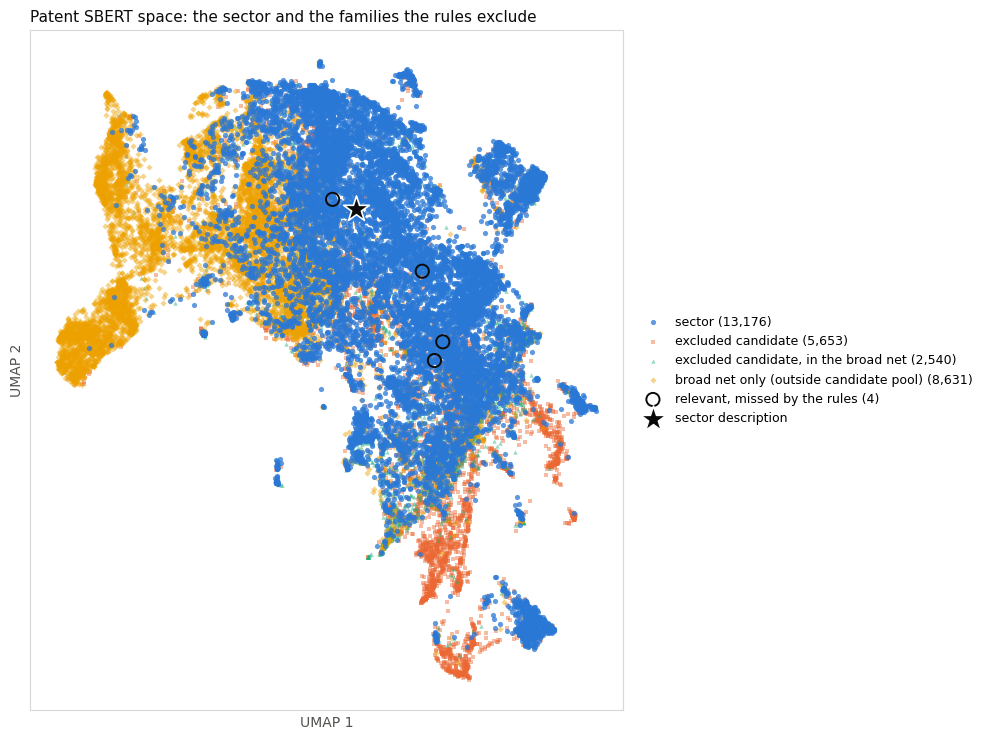

In [26]:
if umap_ok:   # Map 1: sector vs excluded families
    groups = ["sector", "excluded candidate", "excluded candidate, in the broad net", "broad net only (outside candidate pool)"]
    fig, ax = plt.subplots(figsize=(10, 7.5))
    for i, g in enumerate([g for g in groups if g in set(pts["group"])]):
        d = pts[pts["group"] == g]
        ax.scatter(d["UMAP_1"], d["UMAP_2"], s=10 if i else 14, alpha=0.75 if i == 0 else 0.45,
                   color=COLORS[i], marker=MARKERS[i], linewidths=0, label=f"{g} ({len(d):,})", zorder=2 if i == 0 else 1)
    if "disc_label" in pts:
        rel = pts[pts["disc_label"] == 1]
        ax.scatter(rel["UMAP_1"], rel["UMAP_2"], s=90, facecolors="none", edgecolors=INK, linewidths=1.4, zorder=4,
                   label=f"relevant, missed by the rules ({len(rel)})")
    draw_description(ax, desc_xy)
    style(ax, "Patent SBERT space: the sector and the families the rules exclude")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9)
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_sector_vs_excluded.png", dpi=200, bbox_inches="tight")
    plt.show()

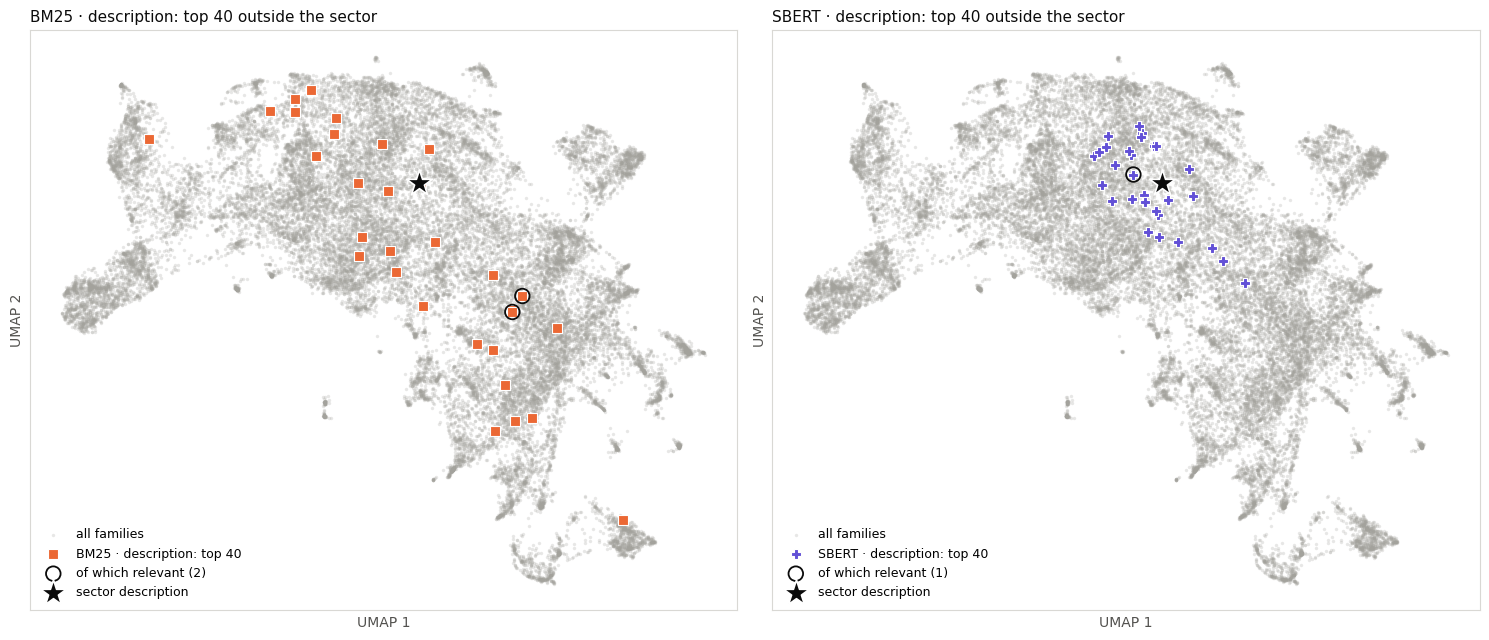

Families in both top-40 lists: 1 (2%)


In [27]:
if umap_ok:   # Map 2: BM25 vs SBERT top-K, same query (sector description)
    pairs_map = [("BM25 · description", COLORS[1], MARKERS[1]), ("SBERT · description", COLORS[5], MARKERS[5])]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
    for ax, (name, color, marker) in zip(axes, pairs_map):
        ax.scatter(pts["UMAP_1"], pts["UMAP_2"], s=6, color=MUTED, alpha=0.25, linewidths=0, label="all families")
        top = pts[pts[f"rank {name}"] <= DISCOVERY_TOP_K]
        ax.scatter(top["UMAP_1"], top["UMAP_2"], s=42, color=color, marker=marker, edgecolor="white",
                   linewidth=0.8, zorder=3, label=f"{name}: top {DISCOVERY_TOP_K}")
        if "disc_label" in pts:
            rel = top[top["disc_label"] == 1]
            ax.scatter(rel["UMAP_1"], rel["UMAP_2"], s=110, facecolors="none", edgecolors=INK, linewidths=1.3,
                       zorder=4, label=f"of which relevant ({len(rel)})")
        draw_description(ax, desc_xy)
        style(ax, f"{name}: top {DISCOVERY_TOP_K} outside the sector")
        ax.legend(loc="lower left", frameon=False, fontsize=9)
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_bm25_vs_sbert.png", dpi=200, bbox_inches="tight")
    plt.show()
    both = ((pts["rank BM25 · description"] <= DISCOVERY_TOP_K) &
            (pts["rank SBERT · description"] <= DISCOVERY_TOP_K)).sum()
    print(f"Families in both top-{DISCOVERY_TOP_K} lists: {both} ({both / DISCOVERY_TOP_K:.0%})")

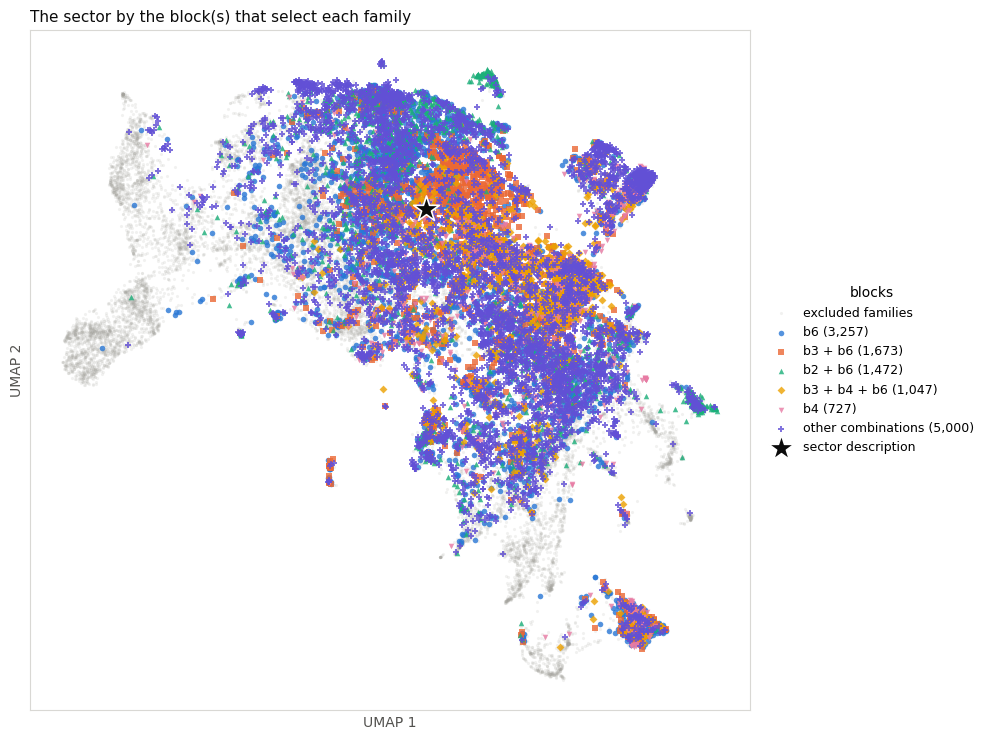

In [28]:
if umap_ok:   # Map 3: the sector by block combination
    sec = pts[pts["group"] == "sector"].copy()
    top_combos = sec["block_combo"].value_counts().index[:5].tolist()   # fixed order: largest first
    sec["combo"] = sec["block_combo"].where(sec["block_combo"].isin(top_combos), "other combinations")
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.scatter(pts["UMAP_1"], pts["UMAP_2"], s=5, color=MUTED, alpha=0.15, linewidths=0, label="excluded families")
    for i, c in enumerate(top_combos + (["other combinations"] if (sec["combo"] == "other combinations").any() else [])):
        d = sec[sec["combo"] == c]
        ax.scatter(d["UMAP_1"], d["UMAP_2"], s=16, color=COLORS[i % len(COLORS)], marker=MARKERS[i % len(MARKERS)],
                   alpha=0.8, linewidths=0, label=f"{c} ({len(d):,})")
    draw_description(ax, desc_xy)
    style(ax, "The sector by the block(s) that select each family")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=9, title="blocks")
    plt.tight_layout()
    fig.savefig(C.OUT_STEP0 / "umap_sector_blocks.png", dpi=200, bbox_inches="tight")
    plt.show()

## 9 · Outputs

| File | Content |
|---|---|
| `sector_families.csv` | one row per sector family (final sector): family year, truncation flag, first office, block and exclusion flags, corrections |
| `candidates_all.csv` | all candidate families with their flags (to reproduce the block analysis) |
| `raw/*.csv.gz` | applications, titles, abstracts, CPC and IPC of the sector families, reused by `02_clean` |
| `block_overlap.png`, `retrieval_evaluation.csv`, `umap_*.png` | figures and tables for the technical appendix |
| `label_sample_sector.csv`, `label_sample_broad_net.csv`, `label_discovery.csv` | files to label (no flags) |
| `label_samples_key.csv`, `discovery_ranks.csv` | flags and method ranks of the families to label (not for labellers) |
| `label_corrections.csv` | families removed or added by the hand-labelled corrections |
| `discovery_precision_at_k.csv`, `step0_summary.csv` | precision@k of BM25 and SBERT outside the sector; the key numbers of Section 10 |

In [29]:
FLAG_COLS = (["docdb_family_id", "family_year", "is_truncated", "first_office", "has_en_abstract"] + FLAGS
             + ["matched", "excluded", "in_sector_application", "in_sector_family", "in_sector_rules",
                "corr_removed", "corr_added", "n_blocks", "block_combo", "in_sector"] + GZ)
sector[FLAG_COLS].to_csv(C.OUT_STEP0 / "sector_families.csv", index=False)
fam[FLAG_COLS].to_csv(C.OUT_STEP0 / "candidates_all.csv", index=False)

ids = set(sector["docdb_family_id"])
apps[apps["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "applications.csv.gz", index=False)
titles[titles["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "titles.csv.gz", index=False)
abstracts[abstracts["docdb_family_id"].isin(ids)].to_csv(C.OUT_STEP0 / "raw" / "abstracts.csv.gz", index=False)
cpc[cpc["docdb_family_id"].isin(ids)][["docdb_family_id", "appln_id", "cpc"]].to_csv(
    C.OUT_STEP0 / "raw" / "cpc.csv.gz", index=False)
if not ipc.empty:
    ipc[ipc["docdb_family_id"].isin(ids)][["docdb_family_id", "appln_id", "ipc"]].to_csv(
        C.OUT_STEP0 / "raw" / "ipc.csv.gz", index=False)

print(f"Saved in {C.OUT_STEP0.resolve()}: {len(sector):,} sector families")

Saved in /home/jovyan/Team10/step0_final/outputs/prod/step0: 15,754 sector families


## 10 · Summary

The key numbers of Step 0 in one table (saved as `step0_summary.csv`), with the checks that are still open.
Only the PROD numbers go in the deck.

In [30]:
def pct(k, n):
    lo, hi = wilson(k, n)
    return f"{k / n:.0%} ({lo:.0%}-{hi:.0%}, {k}/{n})" if n else "n/a"


summary = {"environment": C.ENV, "IPR type": C.IPR_TYPE, "matching level": C.MATCH_LEVEL,
           "families selected by the blocks": int(fam["matched"].sum()),
           "removed by the grey-zone exclusion rules": int((fam["matched"] & fam["excluded"]).sum()),
           "sector given by the rules": len(rule_sector),
           "hand-labelled corrections (removed / added)": f"{int(fam['corr_removed'].sum())} / {int(fam['corr_added'].sum())}",
           "FINAL SECTOR (families)": len(sector),
           "of which truncated": int(sector["is_truncated"].sum())}
summary["labels used for validation"] = f"random PROD samples ({len(lab)} sector families, {len(broad_lab)} broad-net)"
if not lab.empty:
    summary["precision of the rule sector (strict rule, stratified)"] = f"{P_SECTOR:.0%} ({P_CI[0]:.0%}-{P_CI[1]:.0%})"
    summary["precision of the rule sector (broad rule, upper bound)"] = f"{P_SECTOR_BROAD:.0%} ({P_CI_BROAD[0]:.0%}-{P_CI_BROAD[1]:.0%})"
    for h, r in strata_table.iterrows():
        summary[f"precision, stratum {h}"] = pct(int(r["relevant"]), int(r["labelled"])) if r["labelled"] else "NOT LABELLED"
if not np.isnan(RECALL):
    summary["recall relative to the broad net"] = f"{RECALL:.0%} ({RECALL_RANGE[0]:.0%}-{RECALL_RANGE[1]:.0%})"
if not KAPPA.empty:
    for pair, r in KAPPA.iterrows():
        summary[f"kappa {pair}"] = f"{r['kappa']:.2f} on {int(r['families'])} families ({r['agreement']:.0%} agreement)"
checks = {
    "labels found in labels/": not labels.empty,
    "broad-net sample labelled": not broad_lab.empty,
    "discovery sample labelled": not disc_lab.empty,
    "every stratum of the sector labelled": (not lab.empty) and bool((strata_table["labelled"] > 0).all()),
    "second labelling (kappa)": not KAPPA.empty,
    "grey_zone column filled": labels["grey_zone"].ne("").any() if not labels.empty else False,
    "run on PROD": C.ENV == "PROD",
}
summary.update({f"check: {k}": ("yes" if v else "NO") for k, v in checks.items()})
summary_df = pd.Series(summary, name="value").to_frame()
display(summary_df)
summary_df.to_csv(C.OUT_STEP0 / "step0_summary.csv")
if not all(checks.values()):
    print("Provisional: " + ", ".join(k for k, v in checks.items() if not v) + ".")

,value
environment,PROD
IPR type,PI
matching level,family
families selected by the blocks,15949
removed by the grey-zone exclusion rules,173
sector given by the rules,15776
hand-labelled corrections (removed / added),51 / 29
FINAL SECTOR (families),15754
of which truncated,5762
labels used for validation,"random PROD samples (100 sector families, 43 b..."


Provisional: every stratum of the sector labelled, second labelling (kappa).


### 10.1 Flow of the selection (PRISMA-style)

How the candidate pool becomes the final sector, with the validation numbers next to it, in the style of the PRISMA 2020 flow diagram (Page et al., 2021; used for patent datasets by Belabyad et al., 2025). Saved as `prisma_flow.png` (deck, Step 0 slide or technical appendix) and `prisma_counts.csv`. The two `assert`s check that the flow adds up.

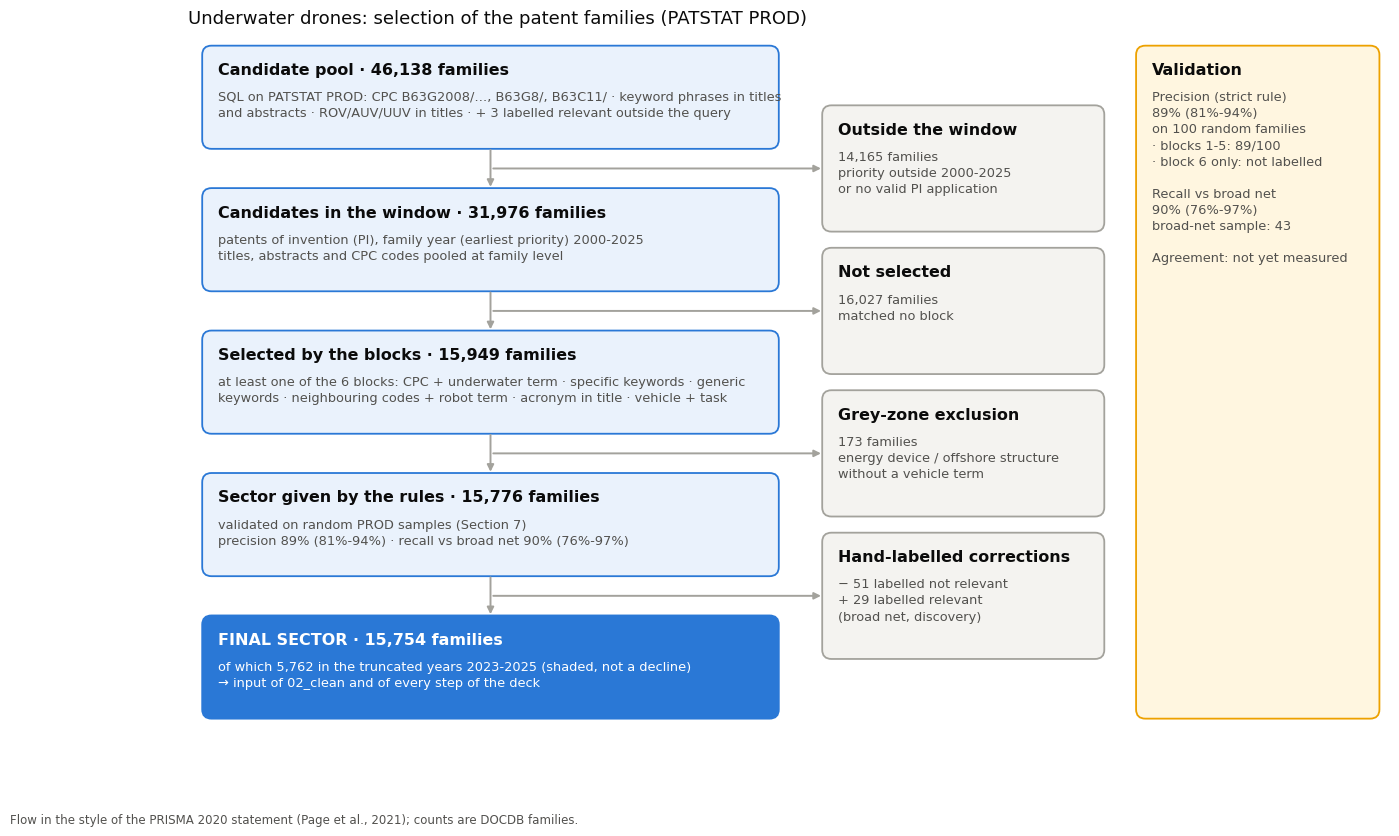

In [31]:
# ---------------------------------------------------------------- 10.1 PRISMA-style flow of the sector selection
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

BLUE, INK, SUB, LINE = "#2a78d6", "#0b0b0b", "#52514e", "#a3a29c"
FILL_MAIN, FILL_OUT, FILL_VAL = "#eaf2fc", "#f4f3f0", "#fff6e0"


def draw_prisma(n, path=None):
    """PRISMA-style diagram (Page et al., 2021) of the sector selection. `n` is a dict of counts and strings."""
    fig, ax = plt.subplots(figsize=(15.5, 9.2))
    ax.set_xlim(0, 15.5); ax.set_ylim(0.9, 10.1); ax.axis("off")

    def box(x, y, w, h, title, body, fill, edge):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    fc=fill, ec=edge, lw=1.3))
        ax.text(x + 0.18, y + h - 0.2, title, ha="left", va="top", fontsize=11.5, fontweight="bold", color=INK)
        ax.text(x + 0.18, y + h - 0.58, body, ha="left", va="top", fontsize=9.3, color=SUB, linespacing=1.45)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", color=LINE, lw=1.4))

    # main column (x 0.3-6.3), excluded column (x 7.0-10.0), stage labels on the far left are in the titles
    X, W, H, XO, WO, HO = 0.2, 7.4, 1.3, 8.2, 3.6, 1.6
    ys = [8.6, 6.75, 4.9, 3.05, 1.2]
    main = [
        (f"Candidate pool · {n['pool']:,} families",
         f"SQL on PATSTAT {n['env']}: CPC B63G2008/…, B63G8/, B63C11/ · keyword phrases in titles\n"
         f"and abstracts · ROV/AUV/UUV in titles · + {n['pool_labelled']:,} labelled relevant outside the query"),
        (f"Candidates in the window · {n['window']:,} families",
         f"patents of invention (PI), family year (earliest priority) {n['years']}\n"
         f"titles, abstracts and CPC codes pooled at family level"),
        (f"Selected by the blocks · {n['matched']:,} families",
         "at least one of the 6 blocks: CPC + underwater term · specific keywords · generic\n"
         "keywords · neighbouring codes + robot term · acronym in title · vehicle + task"),
        (f"Sector given by the rules · {n['rule_sector']:,} families",
         f"validated on random PROD samples (Section 7)\n"
         f"precision {n['precision']} · recall vs broad net {n['recall']}"),
        (f"FINAL SECTOR · {n['final']:,} families",
         f"of which {n['truncated']:,} in the truncated years {n['trunc_years']} (shaded, not a decline)\n"
         f"→ input of 02_clean and of every step of the deck"),
    ]
    outs = [
        ("Outside the window", f"{n['out_window']:,} families\npriority outside {n['years']}\nor no valid PI application"),
        ("Not selected", f"{n['not_matched']:,} families\nmatched no block"),
        ("Grey-zone exclusion", f"{n['excluded']:,} families\nenergy device / offshore structure\nwithout a vehicle term"),
        ("Hand-labelled corrections", f"− {n['corr_removed']:,} labelled not relevant\n+ {n['corr_added']:,} labelled relevant\n(broad net, discovery)"),
    ]
    for i, (y, (t, b)) in enumerate(zip(ys, main)):
        last = i == len(main) - 1
        box(X, y, W, H, t, b, BLUE if last else FILL_MAIN, BLUE)
        if last:   # white text on the final box
            for txt in ax.texts[-2:]:
                txt.set_color("white")
        if i < len(main) - 1:
            arrow(X + W / 2, y, X + W / 2, ys[i + 1] + H)
    for i, (t, b) in enumerate(outs):
        y_mid = (ys[i] + ys[i + 1] + H) / 2
        box(XO, y_mid - HO / 2, WO, HO, t, b, FILL_OUT, LINE)
        arrow(X + W / 2, y_mid, XO, y_mid)

    # validation panel
    box(12.25, 1.2, 3.1, 8.7, "Validation", n["validation"], FILL_VAL, "#eda100")
    ax.set_title(f"{n['sector_name']}: selection of the patent families (PATSTAT {n['env']})", loc="left",
                 fontsize=13, color=INK, pad=6)
    fig.text(0.01, 0.02, "Flow in the style of the PRISMA 2020 statement (Page et al., 2021); counts are DOCDB families.",
             fontsize=8.5, color=SUB)
    if path:
        fig.savefig(path, dpi=200, bbox_inches="tight")
    return fig


def fmt_ci(p, ci):
    return f"{p:.0%} ({ci[0]:.0%}-{ci[1]:.0%})" if p == p else "n/a"


if "__file__" not in globals():   # inside the notebook: counts from the run
    val_lines = [f"Precision (strict rule)\n{fmt_ci(P_SECTOR, P_CI)}",
                 f"on {len(lab)} random families"]
    if not lab.empty:
        for h, r in strata_table.iterrows():
            val_lines.append(f"· {h}: {int(r['relevant'])}/{int(r['labelled'])}" if r["labelled"] else f"· {h}: not labelled")
    val_lines += ["", f"Recall vs broad net\n{fmt_ci(RECALL, RECALL_RANGE)}", f"broad-net sample: {len(broad_lab)}", ""]
    if not KAPPA.empty:
        val_lines.append("Agreement (Cohen's kappa)")
        val_lines += [f"· {pair}: {r['kappa']:.2f}" for pair, r in KAPPA.iterrows()]
    else:
        val_lines.append("Agreement: not yet measured")
    counts = {
        "sector_name": C.SECTOR_NAME, "env": C.ENV, "years": f"{C.YEAR_MIN}-{C.YEAR_MAX}",
        "pool": len(query_pool), "pool_labelled": len(set(pool_ids) - query_pool),
        "window": len(fam), "out_window": len(pool_ids) - len(fam),
        "matched": int(fam["matched"].sum()), "not_matched": int((~fam["matched"]).sum()),
        "excluded": int((fam["matched"] & fam["excluded"]).sum()),
        "rule_sector": len(rule_sector),
        "corr_removed": int(fam["corr_removed"].sum()), "corr_added": int(fam["corr_added"].sum()),
        "final": len(sector), "truncated": int(sector["is_truncated"].sum()),
        "trunc_years": f"{C.LAST_COMPLETE_YEAR + 1}-{C.YEAR_MAX}",
        "precision": fmt_ci(P_SECTOR, P_CI), "recall": fmt_ci(RECALL, RECALL_RANGE),
        "validation": "\n".join(val_lines),
    }
    assert counts["matched"] - counts["excluded"] == counts["rule_sector"], "flow does not add up (exclusions)"
    assert counts["rule_sector"] - counts["corr_removed"] + counts["corr_added"] == counts["final"], "flow does not add up (corrections)"
    draw_prisma(counts, C.OUT_STEP0 / "prisma_flow.png")
    plt.show()
    pd.Series({k: v for k, v in counts.items() if k != "validation"}, name="value").to_csv(C.OUT_STEP0 / "prisma_counts.csv")
